# Exploratory Data Analysis: Spotify × YouTube

**IS428 Visual Analytics · Group 7 · *Engineering the Ultimate Audio Dopamine Trap***

> **Guiding question:** *How are audio features associated with track popularity across Spotify and YouTube?*

This notebook is the proposal's Week 7 milestone: exploratory data analysis and data cleaning. It has two jobs:

1. **Understand the data before any dashboard is built:** what is in it, how clean it is, and what it can and cannot tell us.
2. **Produce a clean, Tableau-ready table** (`dataset/spotify_youtube_clean.csv`) that implements the proposal's popularity definition, ready for Week 8 prototyping.

| # | Question | Section |
|---|---|---|
| Q1 | What is in the dataset, and how clean is it? | §2–3 |
| Q2 | How is popularity distributed on each platform, and how should "popular" be defined? | §4 |
| Q3 | Do Spotify and YouTube agree on what is popular? | §5 |
| Q4 | What do the audio features look like, and how do they relate to each other? | §6 |
| Q5 | Which audio features are associated with popularity on each platform, and what confounds that? | §7 |

§8 summarises the findings and what they mean for the dashboard. §9 writes the clean file.

**How to read the charts:**
- Spotify is always **blue** and YouTube always **orange**. Grey marks are platform-neutral.
- Popularity counts use a **log10 scale** (6 = one million, 9 = one billion).
- Correlations are **Spearman's ρ**, which is rank-based and robust to skew and outliers.

## 1. Setup

Requires `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib` and `seaborn` (see `requirements.txt`). The dataset is found by walking up from the working directory, so the notebook runs from either `notebooks/` or the repo root.

In [ ]:
import re
import unicodedata
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=r"\s*Pyarrow will become a required dependency", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def _format_float(x):
    # Readable floats in tables: 1,234,567 | 12.35 | 0.0442
    if abs(x) >= 1000:
        return f"{x:,.0f}"
    if abs(x) >= 1 or x == 0:
        return f"{x:.2f}"
    return f"{x:.3g}"


pd.set_option("display.float_format", _format_float)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

In [ ]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset" / "Spotify_Youtube.csv").exists())
RAW_PATH = ROOT / "dataset" / "Spotify_Youtube.csv"
CLEAN_PATH = ROOT / "dataset" / "spotify_youtube_clean.csv"

# Continuous audio features; Key is categorical and handled separately
AUDIO_FEATURES = ["Danceability", "Energy", "Loudness", "Speechiness", "Acousticness",
                  "Instrumentalness", "Liveness", "Valence", "Tempo", "Duration_ms"]
FEATURE_LABELS = {"Duration_ms": "Duration (min)", "Loudness": "Loudness (dB)", "Tempo": "Tempo (BPM)"}
POPULARITY = ["Stream", "Views", "Likes", "Comments"]
KEY_NAMES = ["C", "C♯/D♭", "D", "D♯/E♭", "E", "F", "F♯/G♭", "G", "G♯/A♭", "A", "A♯/B♭", "B"]
TIER_LABELS = ["Q1 (Low)", "Q2", "Q3", "Q4 (Top)"]
TOP_TIER = TIER_LABELS[-1]

print("Data file:", RAW_PATH)

Data file: C:\Users\wasd0\OneDrive\Documents\SMU\Y4S1\VA\Project\Visual-Analytics-Group-7\dataset\Spotify_Youtube.csv


In [ ]:
# Colours come from a validated reference palette. Blue and orange stay distinct under
# protanopia/deuteranopia (CVD ΔE 24.7); Spotify-green vs YouTube-red would not.
SPOTIFY, YOUTUBE = "#2a78d6", "#eb6834"
PLATFORM_COLOURS = {"Spotify": SPOTIFY, "YouTube": YOUTUBE}
NEUTRAL, MUTED, FAINT = "#52514e", "#898781", "#c3c2b7"
INK, SURFACE, GRID, MIDPOINT = "#0b0b0b", "#fcfcfb", "#e1e0d9", "#f0efec"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "sequential_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("diverging_blue_red", [SPOTIFY, MIDPOINT, "#e34948"])

installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
ui_font = next((f for f in ["Segoe UI", "Helvetica Neue", "Arial"] if f in installed_fonts), None)

plt.rcParams.update({
    "font.family": [f for f in (ui_font, "DejaVu Sans") if f],  # DejaVu supplies glyphs such as ♯ and ♭
    "font.size": 10,
    "figure.dpi": 100,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.titlesize": 13, "figure.titleweight": "bold",
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": NEUTRAL,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": FAINT, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": FAINT, "ytick.color": FAINT, "xtick.labelcolor": NEUTRAL, "ytick.labelcolor": NEUTRAL,
    "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.solid_capstyle": "round",
    "patch.edgecolor": SURFACE,
})


def human(n):
    '''1_234_567 -> "1.2M": readable counts for labels and tables.'''
    for unit, size in (("B", 1e9), ("M", 1e6), ("K", 1e3)):
        if abs(n) >= size:
            return f"{n / size:.1f}".rstrip("0").rstrip(".") + unit
    return f"{n:,.0f}"


def human_col(series):
    return series.map(lambda v: human(v) if pd.notna(v) else "–")


def log_axis(axis):
    '''Integer ticks on a log10(x + 1) axis, labelled in readable units (0 -> 0, 6 -> 1M).'''
    axis.set_major_locator(mticker.MultipleLocator(1))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: "0" if v == 0 else human(10 ** v) if v > 0 else ""))


def fig_title(fig, text):
    fig.suptitle(text, x=0.01, ha="left")

## 2. Data overview

The raw file is the Kaggle [Spotify and YouTube](https://www.kaggle.com/datasets/salvatorerastelli/spotify-and-youtube) dataset. Its `Description` column holds multi-line YouTube descriptions inside quotes. The file therefore has ~670k physical lines but only ~20.7k records, and `pd.read_csv` handles the quoting.

In [ ]:
raw = pd.read_csv(RAW_PATH)
print(f"{len(raw):,} rows × {raw.shape[1]} columns")
raw.drop(columns=["Description"]).head(3)

20,718 rows × 28 columns


,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Duration_ms,Url_youtube,Title,Channel,Views,Likes,Comments,Licensed,official_video,Stream
0,0,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZuOKwyblJQ,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,0.818,0.705,6.00,-6.68,0.177,0.00836,0.00233,0.613,0.772,138.56,"222,640",https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,"693,555,221","6,220,896","169,907",True,True,"1,040,234,854"
1,1,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZuOKwyblJQ,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,0.676,0.703,8.00,-5.82,0.0302,0.0869,0.000687,0.0463,0.852,92.76,"200,173",https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (Official M...,Gorillaz,"72,011,645","1,079,128","31,003",True,True,"310,083,733"
2,2,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZuOKwyblJQ,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,0.695,0.923,1.00,-3.93,0.0522,0.0425,0.0469,0.116,0.551,108.01,"215,150",https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie Brown (Offi...,Gorillaz,"8,435,055","282,142","7,399",True,True,"63,063,467"


In [ ]:
COLUMN_GROUPS = {  # grouped as in Table 1 of the proposal
    "Popularity (target)": POPULARITY,
    "Audio features": AUDIO_FEATURES + ["Key"],
    "Context": ["Album_type", "Licensed", "official_video", "Artist", "Album"],
    "Identifiers": ["Uri", "Url_youtube"],
    "Other": ["Track", "Title", "Channel", "Description", "Url_spotify", "Unnamed: 0"],
}
column_overview = pd.DataFrame([
    {"group": group, "column": col, "dtype": str(raw[col].dtype), "non-null": raw[col].notna().sum(),
     "unique": raw[col].nunique(), "example": str(raw[col].dropna().iloc[0])[:45]}
    for group, cols in COLUMN_GROUPS.items() for col in cols
])
assert set(column_overview.column) == set(raw.columns)  # every column is accounted for
column_overview

,group,column,dtype,non-null,unique,example
0,Popularity (target),Stream,float64,20142,18461,1040234854.0
1,Popularity (target),Views,float64,20248,19245,693555221.0
2,Popularity (target),Likes,float64,20177,17939,6220896.0
3,Popularity (target),Comments,float64,20149,10485,169907.0
4,Audio features,Danceability,float64,20716,898,0.818
5,Audio features,Energy,float64,20716,1268,0.705
6,Audio features,Loudness,float64,20716,9417,-6.679
7,Audio features,Speechiness,float64,20716,1303,0.177
8,Audio features,Acousticness,float64,20716,3138,0.00836
9,Audio features,Instrumentalness,float64,20716,4012,0.00233


In [ ]:
proposal_audio = AUDIO_FEATURES + ["Key", "Mode"]  # audio features listed in the proposal's Table 1
print("Listed in the proposal but not in the data:", [c for c in proposal_audio if c not in raw.columns])
print("Distinct Url_spotify values per artist:", raw.groupby("Artist").Url_spotify.nunique().max(),
      "-> it is the artist's page, not the track's")

Listed in the proposal but not in the data: ['Mode']
Distinct Url_spotify values per artist: 1 -> it is the artist's page, not the track's


**Observations**

- The file has **20,718 rows and 28 columns**. The proposal rounds this to 20,700 tracks, but only **18,862 are unique tracks** (§3.2).
- **`Mode` (major/minor) is not in this dataset.** The proposal's Table 1 lists it, so either drop it from the report or source it separately from the Spotify API.
- `Unnamed: 0` is a saved pandas index. `Url_spotify` links to the **artist's** page, not the track's; the track identifier is `Uri`.
- `Licensed` and `official_video` load as `object` because they contain missing values. `Key` loads as a float from 0 to 11 (pitch class). Both are fixed in cleaning.

## 3. Data quality

### 3.1 Missing values

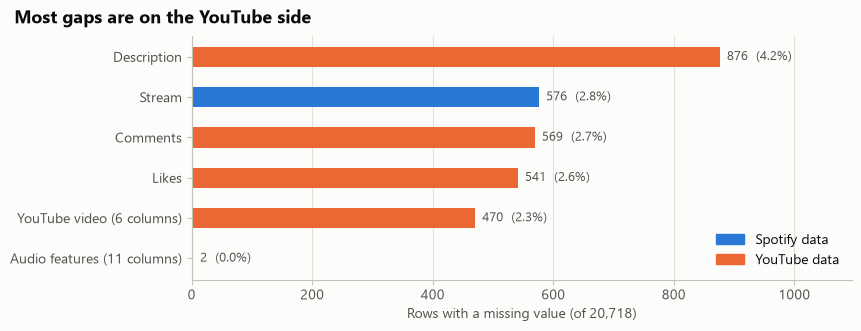

,rows
No YouTube match (all 6 video columns empty together),470
Video exists but like count is hidden,71
Video exists but comment count is missing,99
Video shows 0 comments (comments likely turned off),499
No Spotify stream count,576
No audio features (all 11 empty together),2
Both Stream and Views present,19692


In [ ]:
missing_counts = raw.isna().sum()
yt_video_cols = ["Url_youtube", "Title", "Channel", "Views", "Licensed", "official_video"]
missing_summary = pd.Series({
    "Audio features (11 columns)": missing_counts[AUDIO_FEATURES + ["Key"]].max(),
    "YouTube video (6 columns)": missing_counts[yt_video_cols].max(),
    "Likes": missing_counts["Likes"],
    "Comments": missing_counts["Comments"],
    "Stream": missing_counts["Stream"],
    "Description": missing_counts["Description"],
}).sort_values()
# No other column has gaps
assert missing_counts.drop(AUDIO_FEATURES + ["Key"] + yt_video_cols + ["Likes", "Comments", "Stream", "Description"]).eq(0).all()

source = {"Audio features (11 columns)": "Spotify", "Stream": "Spotify"}
fig, ax = plt.subplots(figsize=(8.5, 3.2), layout="constrained")
ax.barh(missing_summary.index, missing_summary.values, height=0.5,
        color=[PLATFORM_COLOURS[source.get(name, "YouTube")] for name in missing_summary.index])
for y, n in enumerate(missing_summary.values):
    ax.text(n + 12, y, f"{n:,}  ({n / len(raw):.1%})", va="center", fontsize=9, color=NEUTRAL)
ax.set_xlim(0, missing_summary.max() * 1.25)
ax.set_xlabel(f"Rows with a missing value (of {len(raw):,})")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=f"{p} data") for p, c in PLATFORM_COLOURS.items()], loc="lower right")
fig_title(fig, "Most gaps are on the YouTube side")
plt.show()

no_video = raw.Url_youtube.isna()
pd.Series({
    "No YouTube match (all 6 video columns empty together)": raw[yt_video_cols].isna().all(axis=1).sum(),
    "Video exists but like count is hidden": (~no_video & raw.Likes.isna()).sum(),
    "Video exists but comment count is missing": (~no_video & raw.Comments.isna()).sum(),
    "Video shows 0 comments (comments likely turned off)": raw.Comments.eq(0).sum(),
    "No Spotify stream count": raw.Stream.isna().sum(),
    "No audio features (all 11 empty together)": raw[AUDIO_FEATURES + ["Key"]].isna().all(axis=1).sum(),
    "Both Stream and Views present": (raw.Stream.notna() & raw.Views.notna()).sum(),
}, name="rows").to_frame()

**Observations**

- **470 tracks have no YouTube match.** All six video columns are empty together. These tracks can still be used for Spotify-only analysis.
- Likes and Comments have more gaps than Views:
  - 71 videos hide their like count;
  - 99 have no comment count;
  - 499 more show 0 comments (probably turned off).

  This is another reason to use **Views** as the YouTube popularity measure, as the proposal does.
- **576 tracks have no Stream count**, and 2 rows have no audio features at all.
- `Description` has the most gaps (876), but it is free text that isn't used in the analysis.
- **19,692 raw rows have both Stream and Views**, and only these can be compared across platforms. Deduplication (§3.5) reduces this number.

### 3.2 Duplicates

Each row should be one track, but the same track can appear several times. Two questions follow: why does this happen, and what differs between the copies?

In [ ]:
per_artist = raw.groupby("Artist").size()
print(f"{raw.Artist.nunique():,} artists")
per_artist.value_counts().sort_index(ascending=False).rename_axis("rows per artist").rename("artists").to_frame().T

2,079 artists


rows per artist,10,9,8,7,6,3,1
artists,2049,18,1,5,3,1,2


In [ ]:
dup_rows = raw[raw.duplicated("Uri", keep=False)]
group_sizes = dup_rows.groupby("Uri").size()
print(f"Unique tracks (Uri): {raw.Uri.nunique():,} of {len(raw):,} rows -> {len(raw) - raw.Uri.nunique():,} extra rows "
      f"from {len(group_sizes):,} tracks that appear more than once")
display(group_sizes.value_counts().sort_index().rename_axis("copies of the track").rename("tracks").to_frame().T)

largest = group_sizes.nlargest(5)
pd.DataFrame({
    "Track": [raw.loc[raw.Uri == u, "Track"].iloc[0] for u in largest.index],
    "copies": largest.values,
    "credited artists (first 4)": [", ".join(raw.loc[raw.Uri == u, "Artist"].head(4)) for u in largest.index],
})

Unique tracks (Uri): 18,862 of 20,718 rows -> 1,856 extra rows from 1,454 tracks that appear more than once


copies of the track,2,3,4,5,6,7,9,19,24
tracks,1193,211,18,21,2,2,5,1,1


,Track,copies,credited artists (first 4)
0,El Ultimo Adiós - Varios Artistas Version,24,"Alejandro Sanz, Christina Aguilera, Alejandro Fernández,..."
1,Color Esperanza 2020,19,"Nicky Jam, Camilo, Farruko, Thalia"
2,Resistiré,9,"Cristian Castro, Mijares, Mœnia, Gloria Trevi"
3,"Y, ¿Si Fuera Ella? - + Es +",9,"Juanes, Laura Pausini, Antonio Orozco, David Bisbal"
4,"52 Non Stop Dilbar Dilbar Remix(Remix By Kedrock,Sd Style)",9,"Guru Randhawa, Amaal Mallik, Mika Singh, Himesh Reshammiya"


In [ ]:
dup_groups = dup_rows.groupby("Uri")
differs = pd.Series(
    {col: (dup_groups[col].nunique(dropna=False) > 1).sum()
     for col in ["Track", "Danceability", "Energy", "Tempo", "Stream", "Artist", "Url_youtube", "Views"]},
    name=f"tracks (of {len(group_sizes):,}) whose copies disagree")
display(differs.to_frame())

# Example: one song credited to three artists
example_uri = raw.loc[raw.Track == "Leave The Door Open", "Uri"].iloc[0]
raw.loc[raw.Uri == example_uri, ["Artist", "Track", "Stream", "Url_youtube", "Views", "Likes"]]

,"tracks (of 1,454) whose copies disagree"
Track,0
Danceability,0
Energy,0
Tempo,0
Stream,182
Artist,1454
Url_youtube,349
Views,1250


,Artist,Track,Stream,Url_youtube,Views,Likes
14042,Bruno Mars,Leave The Door Open,"1,006,100,004",https://www.youtube.com/watch?v=adLGHcj_fmA,"637,665,698","6,925,257"
15328,Anderson .Paak,Leave The Door Open,"1,006,100,004",https://www.youtube.com/watch?v=adLGHcj_fmA,"637,665,966","6,925,267"
20569,Silk Sonic,Leave The Door Open,"1,006,100,004",https://www.youtube.com/watch?v=adLGHcj_fmA,"637,673,269","6,925,306"


In [ ]:
one_per_track = raw.sort_values("Views", ascending=False, na_position="last").drop_duplicates("Uri")
shared = one_per_track[one_per_track.Url_youtube.notna() & one_per_track.Url_youtube.duplicated(keep=False)]
print(f"Even with one row per track, {shared.Url_youtube.nunique():,} YouTube videos are matched to more than one "
      f"Spotify track ({len(shared):,} rows). Examples:")
(shared.sort_values(["Url_youtube", "Stream"], ascending=[True, False])
       [["Artist", "Track", "Album_type", "Title", "Stream", "Views"]].head(8))

Even with one row per track, 424 YouTube videos are matched to more than one Spotify track (1,047 rows). Examples:


,Artist,Track,Album_type,Title,Stream,Views
2852,Hikaru Utada,Automatic,single,宇多田ヒカル - Automatic,"13,599,505","37,827,084"
2854,Hikaru Utada,Automatic,album,宇多田ヒカル - Automatic,"6,887,516","37,827,084"
7374,Gene Autry,Frosty the Snowman,album,Frosty The Snowman - Gene Autry,"3,959,165","304,144"
7376,Gene Autry,Frosty The Snow Man,compilation,Frosty The Snowman - Gene Autry,"3,108,638","304,144"
13349,Money Man,24 (feat. Lil Baby),album,Money Man - 24 (Official Video) (feat. Lil Baby),"306,160,912","70,540,944"
13350,Money Man,24,album,Money Man - 24 (Official Video) (feat. Lil Baby),"137,384,777","70,540,944"
3874,Wiener Philharmoniker,"Symphony No. 5 in C Minor, Op. 67: I. Allegro con brio",album,Beethoven - Symphony No 5 in C minor Op 67,"48,345,816","598,931"
7804,Philharmonia Orchestra,"Symphony No. 5 in C Minor, Op.67 - I. Allegro con brio",compilation,Beethoven - Symphony No 5 in C minor Op 67,"4,475,285","598,936"


**Observations**

- **2,049 of the 2,079 artists have exactly 10 rows.** The dataset was built from each artist's top 10 Spotify tracks. It is a sample of *successful artists' best tracks*, not of music in general (a survivorship bias), and the "least popular" tier is still an artist's top 10.
- **Duplicates are collaborations.** A track appears once for every credited artist it was scraped under; *Leave The Door Open*, for example, appears under Bruno Mars, Anderson .Paak and Silk Sonic. The largest groups are "various artists" charity singles (24 copies of *El Ultimo Adiós*).
- **Within a group, the Spotify side is identical.** The track name and audio features never differ, and Stream differs in only 182 groups (scrape timing).
- **The YouTube side can differ.** Views drift slightly between scrapes, and in 349 groups a *different video* was matched.
- **Dedup rule:** keep one row per `Uri`, taking the copy with the most-viewed matched video, which is most likely the canonical upload. The number of credited artists is kept as `n_artists`: it records a collaboration, so it is information rather than noise.
- Some **YouTube videos are matched to more than one Spotify track**, such as the single and album releases of one song, or two orchestras' recordings of one symphony. These are flagged `yt_video_shared`, and YouTube statistics count each video once (`yt_primary`).

### 3.3 Anomalies and special content

In [ ]:
anomaly_checks = {
    "Tempo = 0 (audio analysis failed)": raw.Tempo.eq(0),
    "Speechiness > 0.66 (spoken word, Spotify's own cut-off)": raw.Speechiness.gt(0.66),
    "Instrumentalness exactly 0": raw.Instrumentalness.eq(0),
    "Instrumentalness < 0.01": raw.Instrumentalness.lt(0.01),
    "Instrumentalness > 0.5 (instrumental)": raw.Instrumentalness.gt(0.5),
    "Liveness > 0.8 (likely a live recording)": raw.Liveness.gt(0.8),
    "Duration > 10 minutes": raw.Duration_ms.gt(10 * 60_000),
    "Duration < 1 minute": raw.Duration_ms.lt(60_000),
    "Loudness > 0 dB": raw.Loudness.gt(0),
    "Views = 0": raw.Views.eq(0),
    "Comments > Likes": raw.Comments.gt(raw.Likes),
}
pd.DataFrame({"rows": {name: int(mask.sum()) for name, mask in anomaly_checks.items()}}).assign(
    share=lambda d: (d.rows / len(raw)).map("{:.1%}".format))

,rows,share
Tempo = 0 (audio analysis failed),17,0.1%
"Speechiness > 0.66 (spoken word, Spotify's own cut-off)",124,0.6%
Instrumentalness exactly 0,9391,45.3%
Instrumentalness < 0.01,17728,85.6%
Instrumentalness > 0.5 (instrumental),1121,5.4%
Liveness > 0.8 (likely a live recording),385,1.9%
Duration > 10 minutes,76,0.4%
Duration < 1 minute,47,0.2%
Loudness > 0 dB,6,0.0%
Views = 0,1,0.0%


In [ ]:
print("Rows where Spotify's audio analysis failed (Tempo = Danceability = Speechiness = 0):")
raw.loc[raw.Tempo.eq(0), ["Artist", "Track", "Danceability", "Speechiness", "Tempo", "Energy", "Duration_ms"]]

Rows where Spotify's audio analysis failed (Tempo = Danceability = Speechiness = 0):


,Artist,Track,Danceability,Speechiness,Tempo,Energy,Duration_ms
2073,Louis Armstrong,"Hello, Dolly!",0.00,0.00,0.00,0.405,"147,000"
2871,The Alchemist,Arrival,0.00,0.00,0.00,0.802,"94,967"
7187,Luciano Pavarotti,"Rigoletto / Act 3: ""La donna è mobile"" - Live",0.00,0.00,0.00,0.402,"151,253"
8373,M83,Adieux,0.00,0.00,0.00,0.105,"64,840"
9266,Lang Lang,The Departure,0.00,0.00,0.00,0.0362,"151,507"
9348,Ocean Sounds,Beach Waves and Soothing Brown Noise,0.00,0.00,0.00,0.000252,"93,452"
9358,Ocean Waves For Sleep,Beach Waves and Soothing Brown Noise,0.00,0.00,0.00,0.000252,"93,452"
13839,White Noise for Babies,Clean White Noise - Loopable with no fade,0.00,0.00,0.00,0.00342,"90,228"
13840,White Noise for Babies,Pure Brown Noise - Loopable with no fade,0.00,0.00,0.00,0.00125,"72,223"
13842,White Noise for Babies,Air Conditioner - Loopable with no fade,0.00,0.00,0.00,5.5e-05,"108,527"


In [ ]:
print("Artists with the most spoken-word tracks (Speechiness > 0.66):")
display(raw.loc[raw.Speechiness.gt(0.66), "Artist"].value_counts().head(6).to_frame("tracks"))
print("Longest tracks:")
raw.nlargest(5, "Duration_ms")[["Artist", "Track", "Duration_ms"]].assign(minutes=lambda d: (d.Duration_ms / 60_000).round(1))

Artists with the most spoken-word tracks (Speechiness > 0.66):


,tracks
Artist,
Sir Arthur Conan Doyle,10
TKKG,10
Sherlock Holmes,10
Bibi Blocksberg,10
Fünf Freunde,10
Christian Rode,9


Longest tracks:


,Artist,Track,Duration_ms,minutes
10475,Harshdeep Kaur,"High Rated Gabru 52 Non Stop Hits(Remix By Mandy Birgi,B...","4,676,058",77.90
2943,Guru Randhawa,"52 Non Stop Dilbar Dilbar Remix(Remix By Kedrock,Sd Style)","4,581,483",76.40
2983,Amaal Mallik,"52 Non Stop Dilbar Dilbar Remix(Remix By Kedrock,Sd Style)","4,581,483",76.40
4896,Mika Singh,"52 Non Stop Dilbar Dilbar Remix(Remix By Kedrock,Sd Style)","4,581,483",76.40
4926,Himesh Reshammiya,"52 Non Stop Dilbar Dilbar Remix(Remix By Kedrock,Sd Style)","4,581,483",76.40


**Observations**

- **17 rows (13 unique tracks) have Tempo, Danceability and Speechiness all exactly 0.** Spotify's audio analysis failed on them. Most are white-noise and baby-sleep tracks, plus a few classical, ambient and older recordings. These values are placeholders rather than measurements, so the rows are **dropped**.
- **Spoken word** (Speechiness > 0.66, Spotify's own cut-off) is mostly German children's audio dramas (*TKKG*, *Bibi Blocksberg*, *Fünf Freunde*) and Sherlock Holmes audiobooks. It is kept in the clean file but flagged `is_spoken_word`, and it is **excluded from the feature–popularity analysis**: the "danceability of a song" means nothing for an audiobook chapter.
- **Instrumentalness is mostly zeros.** 45% of values are exactly 0 and 86% are below 0.01, so as a continuous variable it says little. A binary `is_instrumental` flag (> 0.5) is more useful for the dashboard.
- **Duration has a long tail** up to ~78 minutes (Indian "52 non-stop" remix medleys). It is flagged `is_long_track` (> 10 min) and converted to minutes.
- Loudness above 0 dB (6 rows) and more comments than likes (4 rows) are rare oddities. They are left alone because they don't change any result.

### 3.4 Cross-platform pairing quality

The cross-platform premise depends on each YouTube video being **the same song** as the Spotify track. The dataset was built by searching YouTube for each track, so a match can be wrong. It can also be a lyric video, a live version or an audio-only upload instead of the music video. There are two checks:

1. **Is the match plausible?** Does the YouTube title contain the track name, or does the title or channel contain the artist?
2. **What kind of video is it?** Each upload is classified from keywords in its title and channel.

In [ ]:
def normalise(text, strip_extras=False):
    '''Lower-case ASCII with punctuation removed; strip_extras drops "(feat. ...)", "[...]" and " - Remastered"-style suffixes.'''
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()
    if strip_extras:
        text = re.sub(r"\(.*?\)|\[.*?\]| - .*$", "", text)
    return " ".join(re.sub(r"[^a-z0-9 ]", " ", text).split())


def title_match(df):
    '''True if the YouTube title contains the track name; <NA> if there is no video or the name is not in Latin script.'''
    track = df["Track"].map(lambda s: normalise(s, strip_extras=True))
    title = df["Title"].map(normalise)
    matched = [t in ti if t else None for t, ti in zip(track, title)]
    return pd.Series(matched, index=df.index, dtype="boolean").mask(df["Title"].isna())


def artist_match(df):
    '''True if the artist name appears in the YouTube title or channel name.'''
    squash = lambda s: s.map(normalise).str.replace(" ", "")
    artist, title, channel = squash(df["Artist"]), squash(df["Title"]), squash(df["Channel"])
    matched = [(a in ti or a in ch) if a else None for a, ti, ch in zip(artist, title, channel)]
    return pd.Series(matched, index=df.index, dtype="boolean").mask(df["Title"].isna())


VIDEO_TYPES = ["Official video", "Lyric video", "Live", "Audio / Topic", "Visualizer", "Other", "No video"]


def classify_video(df):
    '''Label each upload from title/channel keywords; the first matching rule wins.'''
    title = df["Title"].fillna("").str.lower()
    topic_channel = df["Channel"].fillna("").str.endswith("- Topic")
    rules = [
        (df["Title"].isna(), "No video"),
        (title.str.contains(r"official (?:music )?video|official mv|\(mv\)|m/v"), "Official video"),
        (title.str.contains(r"lyric|letra"), "Lyric video"),
        (title.str.contains(r"\blive\b|en vivo|ao vivo"), "Live"),
        (topic_channel | title.str.contains(r"official audio|\(audio\)|audio oficial"), "Audio / Topic"),
        (title.str.contains(r"visuali[sz]er"), "Visualizer"),
    ]
    labels = np.select([cond for cond, _ in rules], [label for _, label in rules], default="Other")
    return pd.Categorical(labels, categories=VIDEO_TYPES)

In [ ]:
pairing = pd.DataFrame({"track_in_title": title_match(raw), "artist_found": artist_match(raw),
                        "video_type": classify_video(raw)})
checkable = pairing.track_in_title.notna()
neither = (pairing.track_in_title.eq(False) & pairing.artist_found.eq(False)).fillna(False).astype(bool)
print(f"Videos: {raw.Title.notna().sum():,}  (track name checkable, i.e. Latin script: {checkable.sum():,})")
print(f"Track name found in the video title:     {pairing.track_in_title[checkable].mean():.1%}")
print(f"Artist found in the title or channel:    {pairing.artist_found.mean():.1%}")
print(f"Neither found (probably the wrong video): {neither.sum():,}")
raw.loc[neither, ["Artist", "Track", "Title", "Channel"]].sample(8, random_state=1)

Videos: 20,248  (track name checkable, i.e. Latin script: 20,139)
Track name found in the video title:     94.4%
Artist found in the title or channel:    91.5%
Neither found (probably the wrong video): 283


,Artist,Track,Title,Channel
4297,Academy of St. Martin in the Fields,Mozart: Concerto For Clarinet And Orchestra In A (K. 622),"Wolfgang Amadeus Mozart: Clarinet Concerto in A major, K...",Iceland Symphony Orchestra
20274,Solfeggio Healing Frequencies MT,528 Hz Love Frequency,432 Hz + 528 Hz DNA Repair & Healing Frequency l Bring P...,Meditation and Healing
2760,Pyotr Ilyich Tchaikovsky,"Tchaikovsky: The Nutcracker, Op. 71, Act II: No. 14a, Pa...","The Nutcracker, Op. 71, Act II: No. 14a, Pas de deux. An...",Sir Simon Rattle - Topic
4449,Anuradha Paudwal,Om Bhurbhuwasah,Gayatri Mantra - Om Bhur Bhuva Swaha | Bhakti Bhajan,Pratima Saran Spiritual
20273,Solfeggio Healing Frequencies MT,528 Hz Anxiety Relief,528Hz + 174Hz || Full Body Relaxation Meditation Music,Meditative Mind
11656,Ramin Djawadi,Main Title (From Game of Thrones: Season 6),Game of Thrones: Season 6 OST - Light of the Seven (EP 1...,Game of Themes
3896,Herbert von Karajan,"Symphony No. 9 in E Minor, Op. 95, B. 178 ""From the New ...","Dvořák: Symphony No. 9 ""From the New World"" / Karajan · ...",Berliner Philharmoniker
5361,Robert Schumann,"Schumann: Davidsbündlertänze, Op. 6, Heft II: No. 14, Za...",Schumann: Davidsbündlertänze Op.6 - XIV,fedomer


In [ ]:
videos = raw.assign(video_type=pairing.video_type).dropna(subset=["Title"])
display(videos.groupby("video_type", observed=True)
        .agg(videos=("Title", "size"),
             share_official_video=("official_video", lambda s: s.eq(True).mean()),
             share_licensed=("Licensed", lambda s: s.eq(True).mean()))
        .sort_values("videos", ascending=False))
pd.crosstab(raw.official_video, raw.Licensed, margins=True)

,videos,share_official_video,share_licensed
video_type,,,
Other,10404,0.673,0.609
Official video,6195,0.893,0.799
Audio / Topic,1829,0.97,0.905
Lyric video,867,0.728,0.616
Live,712,0.789,0.684
Visualizer,241,0.921,0.759


Licensed,False,True,All
official_video,,,
False,4525,0,4525
True,1583,14140,15723
All,6108,14140,20248


**Observations**

- For **~94%** of videos, the YouTube title contains the track name (Latin-script names only), so matching is mostly sound.
- **~280 matches (1.4%) contain neither the track name nor the artist.** Most are classical works, where the video is often a different performance or a differently worded title of the same piece, and generic meditation or "healing frequency" tracks. A few are clearly the wrong song (e.g. a *Game of Thrones* theme matched to a different track from the show). These rows are kept but flagged (`yt_title_match = False`) so Tableau can filter them.
- **`official_video` means "uploaded by an official channel", not "is a music video".** 97% of audio-only uploads on auto-generated "Topic" channels are `official_video = True`.
- The derived **`video_type`** separates real music videos from lyric videos, audio-only uploads and live versions. They attract very different view counts (§7.3).
- About half of the titles carry none of the keywords ("Other", e.g. "Artist - Song"). Many of these are music videos on the artist's VEVO channel, so `video_type` is a rough, conservative label.
- **Every licensed video is also official**, but about 10% of official videos are unlicensed.

### 3.5 Cleaning

Every decision above goes into one `clean()` function, so the clean table can be rebuilt from the raw file in a single call:

| Step | Rule | Why |
|---|---|---|
| 1 | One row per `Uri`, keeping the copy with the most-viewed video; record `n_artists` and `is_collab` | Collaborations appear once per credited artist (§3.2) |
| 2 | Drop rows with no audio features or with `Tempo = 0` | Missing or failed audio analysis (§3.3) |
| 3 | Cast `Licensed` and `official_video` to nullable booleans; add `key_name` and `duration_min` | Correct types, readable values |
| 4 | Add `log_*` = log10(x + 1) for Stream, Views, Likes and Comments; add `like_rate` and `comment_rate` | Counts are extremely skewed (§4.1); the +1 handles Views = 0 |
| 5 | Add the flags `is_spoken_word`, `is_instrumental`, `is_live`, `is_long_track`, `yt_video_shared`, `yt_primary`, `yt_title_match` and `video_type` | Lets the dashboard filter instead of deleting rows |
| 6 | Add quartile tiers `spotify_tier` and `youtube_tier` (Q1 (Low) … Q4 (Top)), plus `spotify_popular` / `youtube_popular` (= Q4) | The proposal's popularity definition (§4.2) |

Tier cut points come from each platform's own de-duplicated set: tracks with a Stream count for Spotify, and one row per video for YouTube. They are then applied to every row.

In [ ]:
def add_tier(df, value_col, basis_mask, tier_col):
    '''Quartile tiers whose cut points come from the rows in basis_mask, applied to every row.'''
    edges = df.loc[basis_mask, value_col].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
    edges[0], edges[-1] = -np.inf, np.inf
    df[tier_col] = pd.cut(df[value_col], bins=edges, labels=TIER_LABELS)
    return edges[1:-1]


def clean(raw):
    '''Apply every cleaning decision from §3. Returns (clean frame, row-count log, tier cut points).'''
    log = [("Raw rows", len(raw))]
    df = raw.drop(columns=["Unnamed: 0"])

    # 1. One row per Spotify track, keeping the copy with the most-viewed video
    n_artists = df.groupby("Uri")["Artist"].nunique()
    df = (df.sort_values("Views", ascending=False, na_position="last")
            .drop_duplicates("Uri").sort_index().copy())
    df["n_artists"] = df["Uri"].map(n_artists)
    df["is_collab"] = df["n_artists"] > 1
    log.append(("One row per Spotify track (dedup on Uri)", len(df)))

    # 2. Unusable audio features
    df = df.dropna(subset=AUDIO_FEATURES)
    log.append(("Drop rows with no audio features", len(df)))
    df = df[df["Tempo"] > 0].copy()
    log.append(("Drop failed audio analyses (Tempo = 0)", len(df)))

    # 3. Types and readable columns
    df["Licensed"] = df["Licensed"].astype("boolean")
    df["official_video"] = df["official_video"].astype("boolean")
    df["Key"] = df["Key"].astype(int)
    df["key_name"] = df["Key"].map(dict(enumerate(KEY_NAMES)))
    df["duration_min"] = df["Duration_ms"] / 60_000

    # 4. Popularity on a log10 scale, plus engagement per view
    for col in POPULARITY:
        df[f"log_{col.lower()}"] = np.log10(df[col] + 1)
    views = df["Views"].where(df["Views"] > 0)
    df["like_rate"] = df["Likes"] / views
    df["comment_rate"] = df["Comments"] / views

    # 5. Flags for filtering
    df["is_spoken_word"] = df["Speechiness"] > 0.66
    df["is_instrumental"] = df["Instrumentalness"] > 0.5
    df["is_live"] = df["Liveness"] > 0.8
    df["is_long_track"] = df["duration_min"] > 10
    df["yt_video_shared"] = df["Url_youtube"].notna() & df["Url_youtube"].duplicated(keep=False)
    first_track_per_video = ~df.sort_values("Stream", ascending=False).duplicated("Url_youtube").reindex(df.index)
    df["yt_primary"] = df["Views"].notna() & first_track_per_video
    df["yt_title_match"] = title_match(df)
    df["video_type"] = classify_video(df)

    # 6. Popularity tiers: the proposal's definition, computed within each platform
    cuts = {
        "Spotify": add_tier(df, "log_stream", df["Stream"].notna(), "spotify_tier"),
        "YouTube": add_tier(df, "log_views", df["yt_primary"], "youtube_tier"),
    }
    for platform in ("spotify", "youtube"):
        tier = df[f"{platform}_tier"]
        df[f"{platform}_popular"] = pd.Series(tier.eq(TOP_TIER), dtype="boolean").mask(tier.isna())

    return df, pd.DataFrame(log, columns=["step", "rows"]), cuts

In [ ]:
df, cleaning_log, TIER_CUTS = clean(raw)
display(cleaning_log)

pd.Series({
    "Tracks with a Spotify Stream count": df.Stream.notna().sum(),
    "Tracks with YouTube Views": df.Views.notna().sum(),
    "Tracks with both": (df.Stream.notna() & df.Views.notna()).sum(),
    "Distinct YouTube videos (yt_primary)": df.yt_primary.sum(),
    "Rows reusing a video already counted for another track": (df.Url_youtube.notna() & ~df.yt_primary).sum(),
    "Collaborations (n_artists > 1)": df.is_collab.sum(),
    "Spoken-word tracks (excluded from feature analysis)": df.is_spoken_word.sum(),
}, name="rows").to_frame()

,step,rows
0,Raw rows,20718
1,One row per Spotify track (dedup on Uri),18862
2,Drop rows with no audio features,18860
3,Drop failed audio analyses (Tempo = 0),18847


,rows
Tracks with a Spotify Stream count,18297
Tracks with YouTube Views,18475
Tracks with both,17945
Distinct YouTube videos (yt_primary),17854
Rows reusing a video already counted for another track,621
Collaborations (n_artists > 1),1450
Spoken-word tracks (excluded from feature analysis),122


In [ ]:
# Analysis frames reused below
spotify = df[df.Stream.notna()]                     # one row per track
youtube = df[df.yt_primary]                         # one row per video
paired = df[df.Stream.notna() & df.yt_primary]      # both measures, each video counted once
music = df[~df.is_spoken_word]                      # feature analyses exclude spoken word
music_sp, music_yt = music[music.Stream.notna()], music[music.yt_primary]
PLATFORM_FRAMES = [("Spotify", music_sp, "spotify_tier", "log_stream"),
                   ("YouTube", music_yt, "youtube_tier", "log_views")]
print(f"spotify {len(spotify):,} | youtube {len(youtube):,} | paired {len(paired):,} | "
      f"music_sp {len(music_sp):,} | music_yt {len(music_yt):,}")

spotify 18,297 | youtube 17,854 | paired 17,380 | music_sp 18,215 | music_yt 17,795


**Observations**

- **20,718 raw rows become 18,847 clean tracks.** Deduplication removes 1,856 rows, and 15 more go because their audio analysis is missing or failed.
- Coverage:
  - 18,297 tracks have Stream;
  - 18,475 have Views;
  - **17,945 have both**.

  Counting each shared video once leaves **17,854 distinct YouTube videos**.
- The analysis frames from here on:
  - Spotify statistics use one row per track;
  - YouTube statistics use one row per video;
  - cross-platform comparisons use the paired set;
  - the feature–popularity analysis excludes spoken word.

## 4. Defining popularity

The dataset has no 0–100 popularity score, so the proposal defines popularity **per platform**: **Stream** for Spotify and **Views** for YouTube, with Likes and Comments as supplementary engagement measures. Each count is log-transformed and split into quartile tiers within its own platform, and a track is "popular" on a platform if it falls in that platform's top tier.

### 4.1 The raw counts are extremely skewed

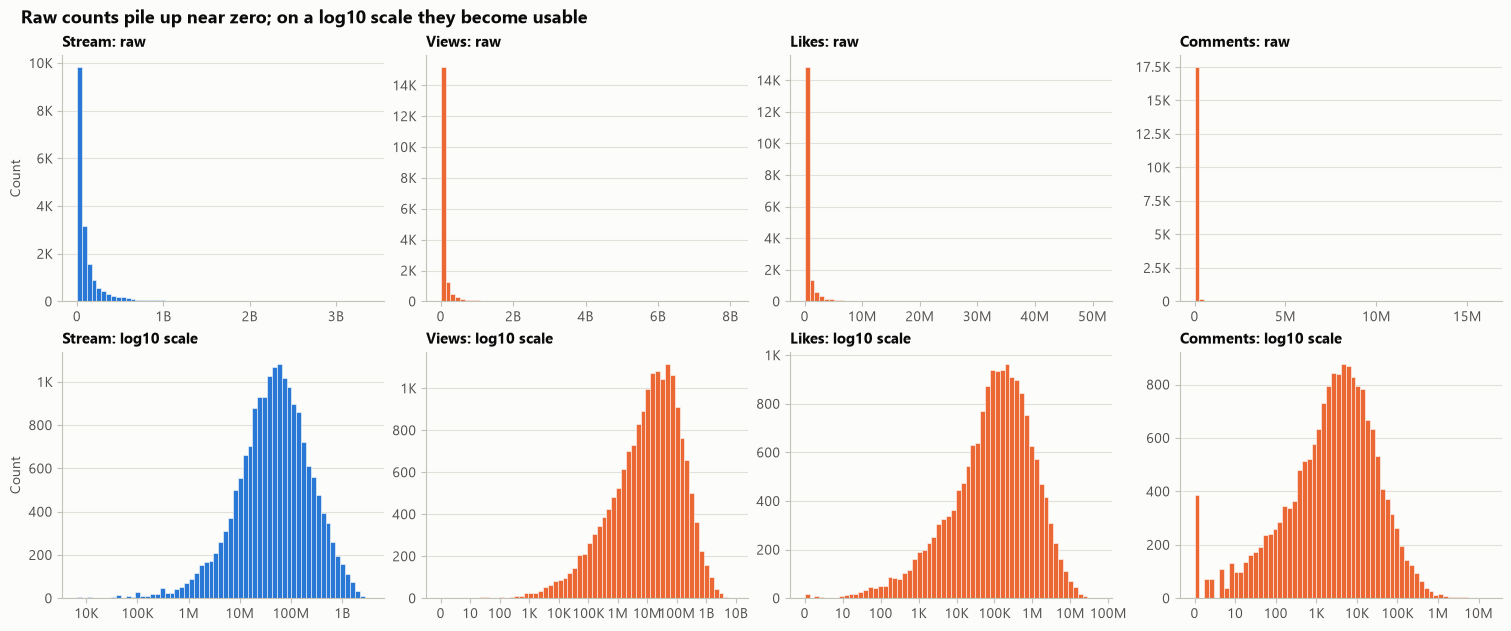

,median,max,skew (raw),skew (log10)
Stream,48.7M,3.4B,4.20,-0.6
Views,13.6M,8.1B,9.10,-0.8
Likes,115.4K,50.8M,8.40,-0.8
Comments,3.1K,16.1M,45.50,-0.7


In [ ]:
metrics = [("Stream", spotify, SPOTIFY), ("Views", youtube, YOUTUBE),
           ("Likes", youtube, YOUTUBE), ("Comments", youtube, YOUTUBE)]

fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), layout="constrained")
skew_rows = {}
for j, (col, data, colour) in enumerate(metrics):
    values = data[col].dropna()
    logged = np.log10(values + 1)
    skew_rows[col] = {"median": human(values.median()), "max": human(values.max()),
                      "skew (raw)": round(values.skew(), 1), "skew (log10)": round(logged.skew(), 1)}
    axes[0, j].hist(values, bins=60, color=colour, edgecolor=SURFACE, linewidth=0.4)
    axes[0, j].set_title(f"{col}: raw")
    axes[0, j].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: human(v)))
    axes[1, j].hist(logged, bins=60, color=colour, edgecolor=SURFACE, linewidth=0.4)
    axes[1, j].set_title(f"{col}: log10 scale")
    log_axis(axes[1, j].xaxis)
    for ax in axes[:, j]:
        ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: human(v)))
axes[0, 0].set_ylabel("Count")
axes[1, 0].set_ylabel("Count")
fig_title(fig, "Raw counts pile up near zero; on a log10 scale they become usable")
plt.show()
pd.DataFrame(skew_rows).T

**Observations**

- The raw counts are extremely right-skewed: skew is ~4 for Stream, ~9 for Views and ~45 for Comments. A few billion-play hits squash everything else into the first bar, so raw means are meaningless and any raw-scale chart or linear model would be dominated by a handful of tracks.
- On a log10 scale the distributions are close to symmetric, which supports **the proposal's log transform**. YouTube keeps a longer left tail of videos with only thousands of views, which is typical of unofficial uploads. The spike at 0 in Comments is the videos with comments turned off.
- The median track has ~49M Spotify streams and ~14M YouTube views: this is already a catalogue of successful music.

### 4.2 Popularity tiers

Quartiles are **rank-based**, so the tiers are identical whether they are cut on raw or log values, as the check below confirms. The log transform matters for plots and linear models, not for tier membership.

Spotify tiers identical on raw vs log10 streams: True


,Spotify streams,YouTube views
Q1 | Q2 boundary (25th percentile),17M,1.8M
Q2 | Q3 boundary (median),48.7M,13.6M
Q3 | Q4 boundary (75th percentile),134.7M,65.5M


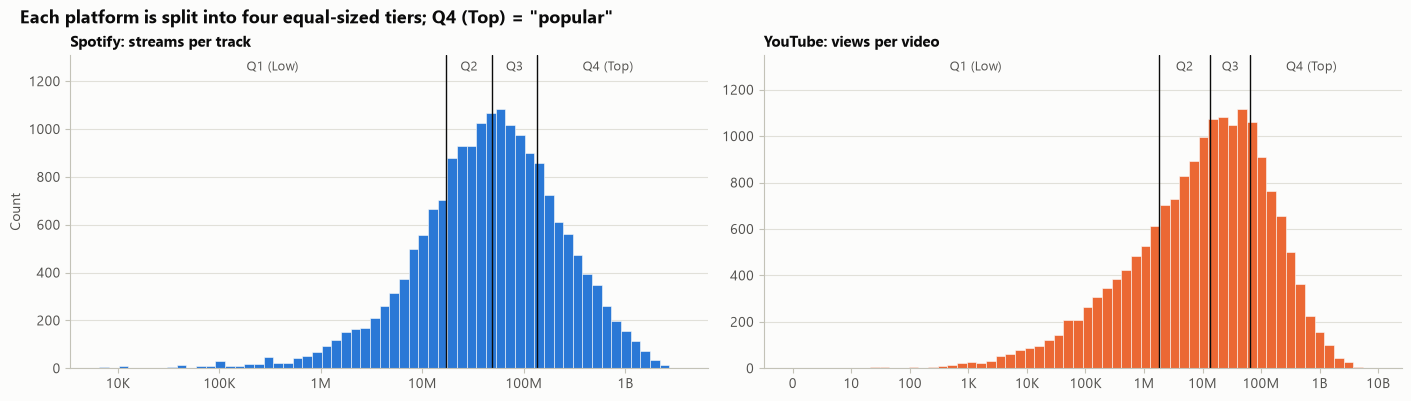

,Spotify tracks,YouTube videos
Q1 (Low),4575,4464
Q2,4574,4463
Q3,4574,4463
Q4 (Top),4574,4464


In [ ]:
same_tiers = pd.qcut(spotify.Stream, 4, labels=TIER_LABELS).equals(pd.qcut(spotify.log_stream, 4, labels=TIER_LABELS))
print("Spotify tiers identical on raw vs log10 streams:", same_tiers)

cut_table = pd.DataFrame(
    {f"{platform} {unit}": [human(10 ** c - 1) for c in TIER_CUTS[platform]]
     for platform, unit in [("Spotify", "streams"), ("YouTube", "views")]},
    index=["Q1 | Q2 boundary (25th percentile)", "Q2 | Q3 boundary (median)", "Q3 | Q4 boundary (75th percentile)"])
display(cut_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), layout="constrained")
for ax, (name, data, col, colour, unit) in zip(axes, [("Spotify", spotify, "log_stream", SPOTIFY, "streams per track"),
                                                      ("YouTube", youtube, "log_views", YOUTUBE, "views per video")]):
    ax.hist(data[col], bins=60, color=colour, edgecolor=SURFACE, linewidth=0.4)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.15)  # headroom for the tier labels
    cuts = TIER_CUTS[name]
    for c in cuts:
        ax.axvline(c, color=INK, linewidth=1)
    bounds = [data[col].min(), *cuts, data[col].max()]
    for label, lo, hi in zip(TIER_LABELS, bounds[:-1], bounds[1:]):
        ax.text((lo + hi) / 2, 0.98, label, transform=ax.get_xaxis_transform(), ha="center", va="top",
                fontsize=9, color=NEUTRAL)
    log_axis(ax.xaxis)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{name}: {unit}")
axes[0].set_ylabel("Count")
fig_title(fig, "Each platform is split into four equal-sized tiers; Q4 (Top) = \"popular\"")
plt.show()

pd.DataFrame({"Spotify tracks": spotify.spotify_tier.value_counts(sort=False),
              "YouTube videos": youtube.youtube_tier.value_counts(sort=False)})

**Observations**

- **"Popular" (Q4) means at least ~135M streams on Spotify, or at least ~66M views on YouTube.**
- The middle half of Spotify tracks spans ~17M–135M streams (~8×). The middle half of YouTube videos spans ~1.8M–66M views (~36×). **YouTube popularity is far more unequal**: the same step up one tier takes much more on YouTube.
- Every track is already one of an artist's top 10, so "Q1 (Low)" means *less popular among hits*, not unpopular. The dashboard should say so.

### 4.3 Likes and Comments as supplementary engagement measures

,Views,Likes,Comments
Views,1.00,0.96,0.91
Likes,0.96,1.00,0.95
Comments,0.91,0.95,1.00


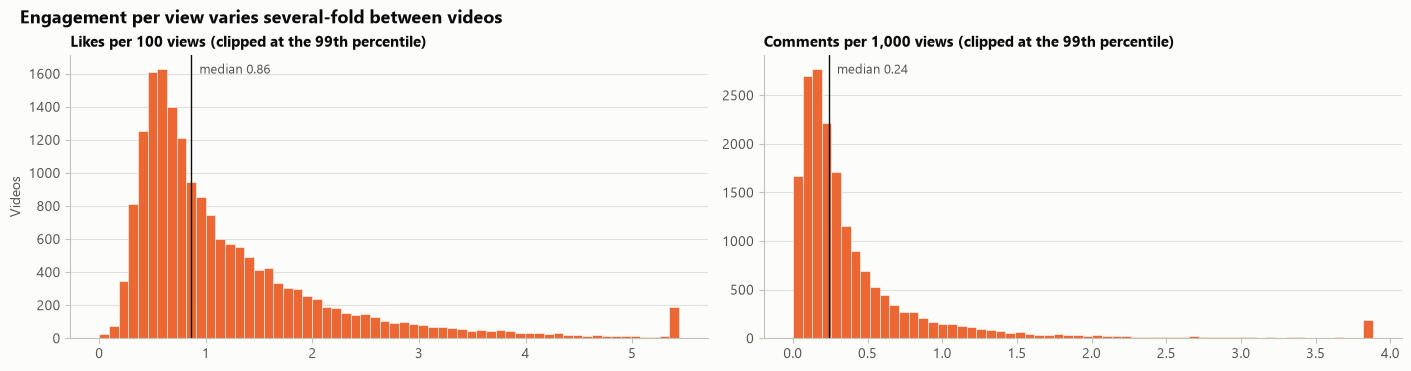

,Spearman ρ with log views
like_rate,-0.485
comment_rate,-0.32


In [ ]:
display(youtube[["Views", "Likes", "Comments"]].corr(method="spearman").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), layout="constrained")
for ax, (col, scale, label) in zip(axes, [("like_rate", 100, "Likes per 100 views"),
                                          ("comment_rate", 1000, "Comments per 1,000 views")]):
    rate = youtube[col].dropna() * scale
    ax.hist(rate.clip(upper=rate.quantile(0.99)), bins=60, color=YOUTUBE, edgecolor=SURFACE, linewidth=0.4)
    ax.axvline(rate.median(), color=INK, linewidth=1)
    ax.text(rate.median(), 0.97, f"  median {rate.median():.2f}", transform=ax.get_xaxis_transform(),
            va="top", fontsize=9, color=NEUTRAL)
    ax.set_title(f"{label} (clipped at the 99th percentile)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Videos")
fig_title(fig, "Engagement per view varies several-fold between videos")
plt.show()

pd.Series({col: stats.spearmanr(youtube.log_views, youtube[col], nan_policy="omit").statistic
           for col in ["like_rate", "comment_rate"]}, name="Spearman ρ with log views").to_frame()

**Observations**

- Views, Likes and Comments move almost in lockstep (Spearman ρ ≈ 0.96 for Views–Likes and 0.91 for Views–Comments). As **popularity** measures, Likes and Comments add little beyond Views.
- Engagement **rates** are the more informative supplementary measure. The median video gets 0.86 likes per 100 views and 0.24 comments per 1,000 views, and rates vary several-fold between videos.
- **More-viewed videos have clearly lower rates** (ρ ≈ −0.49 for like-rate). Mass reach brings in passive viewers, while small videos are watched mostly by committed fans. A like-rate therefore measures intensity of engagement, not popularity.
- **For the dashboard:** base YouTube popularity tiers on Views, and offer like-rate as an optional "engagement" lens rather than as a second popularity metric.

### 4.4 Sanity check: the most popular tracks on each platform

In [ ]:
print("Top 10 on Spotify (streams):")
display(spotify.nlargest(10, "Stream")[["Artist", "Track", "Stream", "Views"]]
        .assign(Stream=lambda d: human_col(d.Stream), Views=lambda d: human_col(d.Views)).reset_index(drop=True))
print("Top 10 on YouTube (views):")
display(youtube.nlargest(10, "Views")[["Artist", "Track", "Views", "Stream"]]
        .assign(Views=lambda d: human_col(d.Views), Stream=lambda d: human_col(d.Stream)).reset_index(drop=True))
overlap = set(spotify.nlargest(10, "Stream").Uri) & set(youtube.nlargest(10, "Views").Uri)
print(f"Tracks in both top-10 lists: {len(overlap)}")

Top 10 on Spotify (streams):


,Artist,Track,Stream,Views
0,The Weeknd,Blinding Lights,3.4B,674.2M
1,Ed Sheeran,Shape of You,3.4B,5.9B
2,Lewis Capaldi,Someone You Loved,2.6B,586.8M
3,Post Malone,rockstar (feat. 21 Savage),2.6B,1.1B
4,Post Malone,Sunflower - Spider-Man: Into the Spider-Verse,2.5B,2B
5,Drake,One Dance,2.5B,169.3M
6,Halsey,Closer,2.5B,455.9M
7,Imagine Dragons,Believer,2.4B,2.4B
8,The Kid LAROI,STAY (with Justin Bieber),2.4B,681.2M
9,Camila Cabello,Señorita,2.3B,1.5B


Top 10 on YouTube (views):


,Artist,Track,Views,Stream
0,Luis Fonsi,Despacito,8.1B,1.5B
1,Ed Sheeran,Shape of You,5.9B,3.4B
2,Charlie Puth,See You Again (feat. Charlie Puth),5.8B,1.5B
3,CoComelon,Wheels on the Bus,4.9B,83.4M
4,Mark Ronson,Uptown Funk (feat. Bruno Mars),4.8B,1.7B
5,PSY,Gangnam Style (강남스타일),4.7B,371M
6,Maroon 5,Sugar,3.8B,1.5B
7,Katy Perry,Roar,3.7B,884.7M
8,OneRepublic,Counting Stars,3.7B,1.8B
9,Justin Bieber,Sorry,3.6B,1.7B


Tracks in both top-10 lists: 1


**Observations**

- The leaders are recognisable global hits (*Blinding Lights* and *Shape of You* at 3.4B streams; *Despacito* at 8.1B views). This confirms that the popularity columns and the deduplication behave as expected.
- **Only *Shape of You* appears in both top-10 lists.** YouTube's list includes video-driven phenomena that are only moderate hits on Spotify: *Wheels on the Bus* (CoComelon, 4.9B views but 83M streams) and *Gangnam Style* (4.7B views, 371M streams). The platforms reward different things at the very top, as the next section examines.

## 5. Do Spotify and YouTube agree?

The proposal treats the two platforms as parallel targets. Before comparing their audio preferences, the first question is how far they agree on *which* tracks are popular. Every comparison here uses the paired set: tracks with both measures, with each video counted once.

### 5.1 Streams vs views

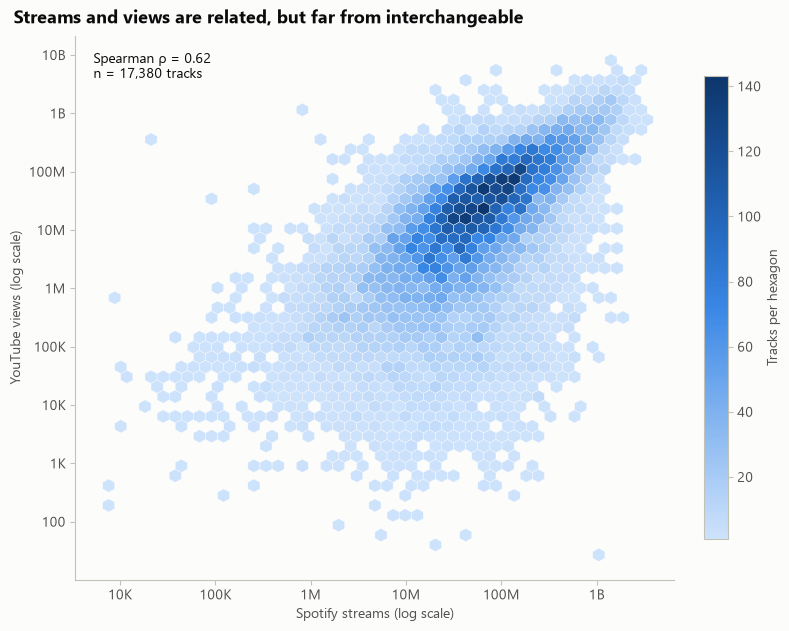

In [ ]:
rho_platforms = stats.spearmanr(paired.log_stream, paired.log_views).statistic

fig, ax = plt.subplots(figsize=(7.8, 6.2), layout="constrained")
hb = ax.hexbin(paired.log_stream, paired.log_views, gridsize=45, cmap=SEQ_CMAP, mincnt=1,
               linewidths=0.3, edgecolors=SURFACE)
fig.colorbar(hb, ax=ax, label="Tracks per hexagon", shrink=0.85)
log_axis(ax.xaxis)
log_axis(ax.yaxis)
ax.set_xlabel("Spotify streams (log scale)")
ax.set_ylabel("YouTube views (log scale)")
ax.grid(False)
ax.text(0.03, 0.97, f"Spearman ρ = {rho_platforms:.2f}\nn = {len(paired):,} tracks", transform=ax.transAxes,
        va="top", fontsize=10, color=INK)
fig_title(fig, "Streams and views are related, but far from interchangeable")
plt.show()

**Observations**

- **ρ ≈ 0.62.** Tracks that are popular on one platform tend to be popular on the other, but the band is wide: at any given stream count, views range across two or more orders of magnitude.
- Popularity on one platform therefore can't stand in for the other, which supports the proposal's decision to model the platforms as **separate, parallel targets**.

### 5.2 Tier agreement

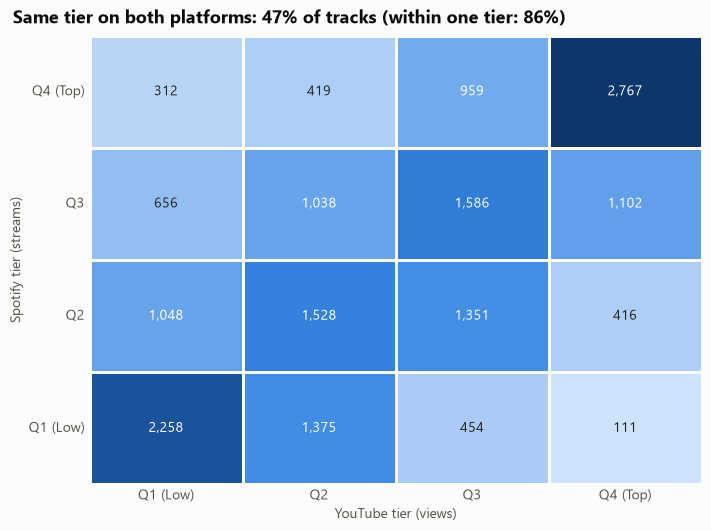

Spotify-only hits (Spotify Q4, YouTube Q1): 312
YouTube-only hits (YouTube Q4, Spotify Q1): 111


,Spotify-only hits,YouTube-only hits,All paired tracks
video_type,,,
Official video,0.25,0.1,0.31
Lyric video,0.04,0.05,0.04
Live,0.03,0.05,0.03
Audio / Topic,0.06,0.00,0.09
Visualizer,0.01,0.00,0.01
Other,0.62,0.81,0.51


In [ ]:
tier_ct = pd.crosstab(paired.spotify_tier, paired.youtube_tier)
total = tier_ct.to_numpy().sum()
exact = np.trace(tier_ct.to_numpy()) / total
within_one = sum(tier_ct.iat[i, j] for i in range(4) for j in range(4) if abs(i - j) <= 1) / total

fig, ax = plt.subplots(figsize=(7, 5.2), layout="constrained")
sns.heatmap(tier_ct.iloc[::-1], annot=True, fmt=",.0f", cmap=SEQ_CMAP, cbar=False, linewidths=2,
            linecolor=SURFACE, annot_kws={"fontsize": 10}, ax=ax)
ax.set_xlabel("YouTube tier (views)")
ax.set_ylabel("Spotify tier (streams)")
ax.grid(False)
ax.tick_params(length=0)
ax.tick_params(axis="y", rotation=0)
fig_title(fig, f"Same tier on both platforms: {exact:.0%} of tracks (within one tier: {within_one:.0%})")
plt.show()

spotify_only = paired[(paired.spotify_tier == TOP_TIER) & (paired.youtube_tier == TIER_LABELS[0])]
youtube_only = paired[(paired.youtube_tier == TOP_TIER) & (paired.spotify_tier == TIER_LABELS[0])]
print(f"Spotify-only hits (Spotify Q4, YouTube Q1): {len(spotify_only):,}")
print(f"YouTube-only hits (YouTube Q4, Spotify Q1): {len(youtube_only):,}")
pd.DataFrame({"Spotify-only hits": spotify_only.video_type.value_counts(normalize=True),
              "YouTube-only hits": youtube_only.video_type.value_counts(normalize=True),
              "All paired tracks": paired.video_type.value_counts(normalize=True)}).round(2).loc[lambda d: d.sum(axis=1) > 0]

In [ ]:
show_cols = ["Artist", "Track", "Stream", "Views", "video_type", "Title"]
print("Biggest Spotify-only hits:")
display(spotify_only.nlargest(6, "Stream")[show_cols]
        .assign(Stream=lambda d: human_col(d.Stream), Views=lambda d: human_col(d.Views)))
print("Biggest YouTube-only hits:")
display(youtube_only.nlargest(6, "Views")[show_cols]
        .assign(Stream=lambda d: human_col(d.Stream), Views=lambda d: human_col(d.Views)))

Biggest Spotify-only hits:


,Artist,Track,Stream,Views,video_type,Title
14072,Justin Bieber,Love Yourself,2B,273.2K,Official video,Justin Bieber - Love Yourself (Official Video)
1777,Journey,Don't Stop Believin',1.5B,643.3K,Official video,Don't Stop Believing [Official Music Video]
17217,XXXTENTACION,Everybody Dies In Their Nightmares,1.3B,290.2K,Other,XXXTENTACION - Everybody Dies In Their Nightmares (Music...
2017,Lynyrd Skynyrd,Sweet Home Alabama,1B,586.4K,Other,Lynyrd Skynyrd - Sweet Home Alabama (1974)
9572,Maroon 5,"Moves Like Jagger - Studio Recording From ""The Voice"" Pe...",1B,26,Lyric video,Moves Like Jagger - Studio Recording From The Voice Perf...
8001,Queen,We Will Rock You - Remastered 2011,988.6M,918.2K,Lyric video,Queen - We will rock you - Remastered [HD] - with lyrics


Biggest YouTube-only hits:


,Artist,Track,Stream,Views,video_type,Title
2566,Coolio,Gangsta's Paradise,725.1K,1.2B,Official video,Coolio - Gangsta's Paradise (feat. L.V.) [Official Music...
11215,Kailash Kher,Kaun Hain Voh,13.9M,576.6M,Other,Kaun Hain Voh - Full Video | Baahubali - The Beginning ...
9195,Ajay-Atul,Zingaat,15.4M,416.2M,Other,Zingaat - Official Full Video | Sairat | Akash Thosar & ...
7545,Eiffel 65,Blue KNY Factory Remix - KNY Factory Remix,1.4M,395.3M,Other,Eiffel 65 - Blue (KNY Factory Remix)
4450,Anuradha Paudwal,Tamma Tamma Again,14.7M,356.8M,Other,"Tamma Tamma Again | Varun , Alia | Bappi L, Anuradha P |..."
4901,Mika Singh,Hawa Hawa,10.9M,351.9M,Other,"""Hawa Hawa"" (Full Video Song) | Mubarakan | Anil Kapoor,..."


**Observations**

- **Fewer than half of tracks (47%) sit in the same tier on both platforms**, although 86% are within one tier. "Popular" on one platform often means only "above average" on the other.
- **Spotify-only hits** (Spotify Q4, YouTube Q1: 312 tracks) are about 3× as common as YouTube-only hits (111).
- **The biggest Spotify-only hits are matching artefacts.** They are global hits whose matched video is clearly not the song's main upload: *Love Yourself* has 2B streams, but its matched video has only 273K views, and *Moves Like Jagger*'s has 26. **`Views` measures the matched upload, not the song's total YouTube audience.** That caveat belongs in the report.
- **The biggest YouTube-only hits are Indian film songs** (*Kaun Hain Voh* from *Baahubali*, *Zingaat* from *Sairat*), from a market where film-song videos are the main way people listen. There are also mirror-image artefacts: *Gangsta's Paradise* is matched to a minor Spotify release with only 725K streams.

### 5.3 Platform lean: which tracks do better on YouTube than their streams predict?

**How the lean is measured:**
1. Fit the overall trend of log views on log streams.
2. Keep each track's **residual** (`lean_score`). A residual of +1 means 10× more views than is typical for a track with the same streams.
3. Label the bottom 20% of residuals *Spotify-leaning*, the top 20% *YouTube-leaning*, and the rest *Balanced*.

This is a **descriptive** divergence measure for the proposal's "medium-specific preferences" gap. It is never used to predict either platform.

Trend: log10(views) ≈ -0.77 + 1.01 × log10(streams)


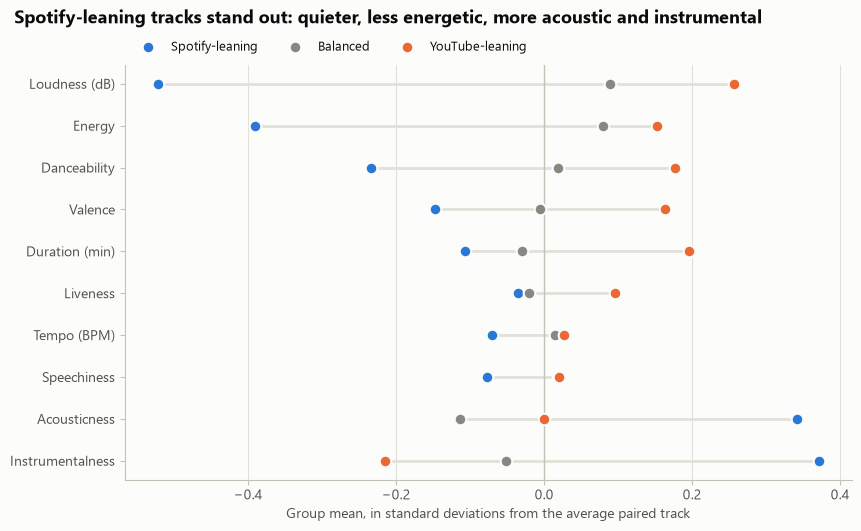

,tracks,official_video = True,video_type: Official video,video_type: Audio / Topic,instrumental
Spotify-leaning,3476,0.49,0.17,0.18,0.13
Balanced,10428,0.83,0.36,0.09,0.04
YouTube-leaning,3476,0.91,0.28,0.01,0.01


In [ ]:
slope, intercept = np.polyfit(paired.log_stream, paired.log_views, 1)
lean_score = paired.log_views - (intercept + slope * paired.log_stream)
lean = pd.qcut(lean_score, [0, 0.2, 0.8, 1], labels=["Spotify-leaning", "Balanced", "YouTube-leaning"])
df["lean_score"] = lean_score       # aligned on the index; empty outside the paired set
df["platform_lean"] = lean
print(f"Trend: log10(views) ≈ {intercept:.2f} + {slope:.2f} × log10(streams)")

LEAN_COLOURS = {"Spotify-leaning": SPOTIFY, "Balanced": MUTED, "YouTube-leaning": YOUTUBE}
profile = paired[AUDIO_FEATURES].assign(Duration_ms=paired.duration_min)
lean_profile = ((profile - profile.mean()) / profile.std()).groupby(lean, observed=True).mean().T
lean_profile = lean_profile.loc[(lean_profile["YouTube-leaning"] - lean_profile["Spotify-leaning"]).sort_values().index]
ypos = np.arange(len(lean_profile))

fig, ax = plt.subplots(figsize=(8.5, 5.2), layout="constrained")
ax.axvline(0, color=FAINT, linewidth=1)
ax.hlines(ypos, lean_profile.min(axis=1), lean_profile.max(axis=1), color=GRID, linewidth=2, zorder=1)
for group, colour in LEAN_COLOURS.items():
    ax.scatter(lean_profile[group], ypos, s=70, color=colour, edgecolor=SURFACE, linewidth=1.5, zorder=3, label=group)
ax.set_yticks(ypos, [FEATURE_LABELS.get(f, f) for f in lean_profile.index])
ax.set_xlabel("Group mean, in standard deviations from the average paired track")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, fontsize=9)
fig_title(fig, "Spotify-leaning tracks stand out: quieter, less energetic, more acoustic and instrumental")
plt.show()

pd.DataFrame({
    "tracks": lean.value_counts(sort=False),
    "official_video = True": paired.official_video.eq(True).groupby(lean, observed=True).mean(),
    "video_type: Official video": paired.video_type.eq("Official video").groupby(lean, observed=True).mean(),
    "video_type: Audio / Topic": paired.video_type.eq("Audio / Topic").groupby(lean, observed=True).mean(),
    "instrumental": paired.is_instrumental.groupby(lean, observed=True).mean(),
}).round(2)

**Observations**

- **On the surface this looks like a "medium-specific audio preference".** The Spotify-leaning group is the outlier: about 0.5 SD quieter and 0.4 SD less energetic than average, and far more acoustic and instrumental. YouTube-leaning tracks are only modestly louder, more energetic and happier than Balanced ones.
- **But the video matters as much as the audio.** Only 49% of Spotify-leaning tracks have an official video, against 91% of YouTube-leaning tracks. Compared with YouTube-leaning tracks, Spotify-leaning tracks are far more often instrumental (13% vs 1%) and far more often matched to an audio-only upload (18% vs 1%). These are catalogues with no real music video, such as classical, ambient and focus or sleep music. **Any cross-platform audio difference has to be read alongside video type** (§7.3).
- `lean_score` and `platform_lean` are exported for the dashboard's divergence view.

## 6. Audio features

Most of Spotify's audio features are 0–1 scores computed from the audio. The exceptions are Loudness (dB), Tempo (BPM) and Duration (ms, shown here in minutes). This section describes their distributions across all clean tracks, and how they relate to each other within music tracks.

### 6.1 Distributions

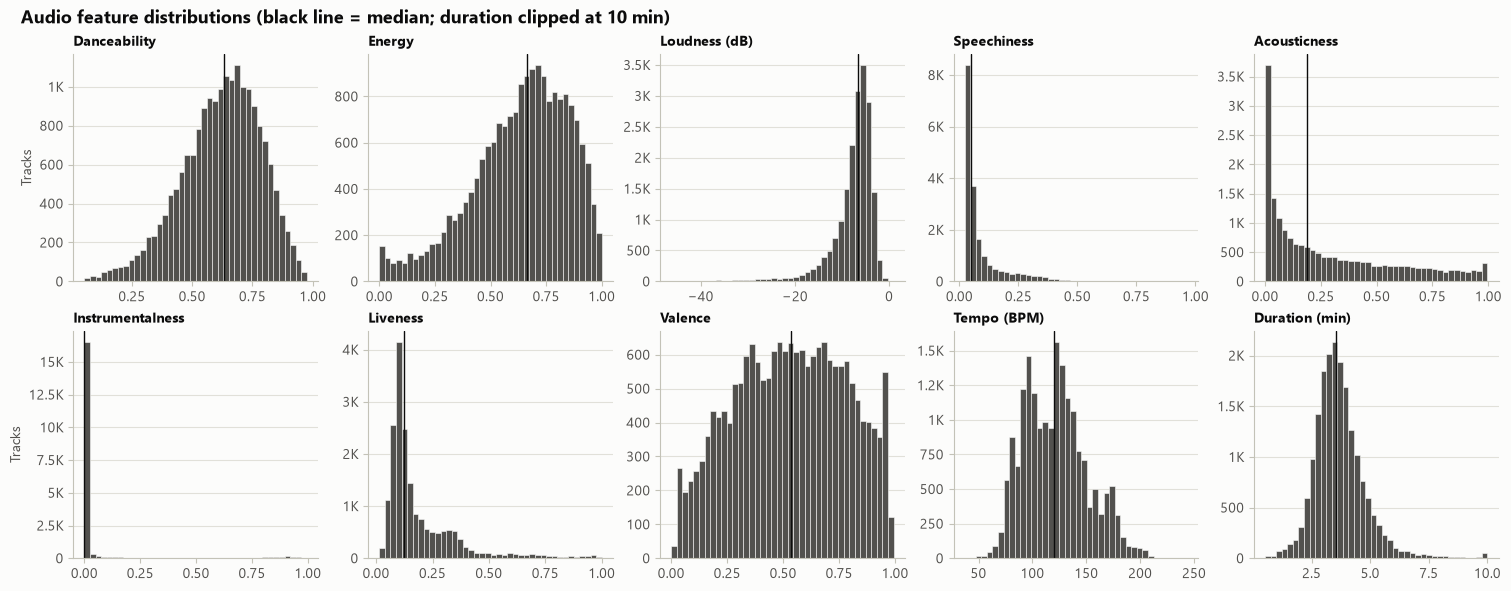

,mean,std,min,25%,50%,75%,max,skew
Danceability,0.618,0.164,0.0532,0.515,0.634,0.738,0.975,-0.493
Energy,0.635,0.215,2.03e-05,0.503,0.666,0.8,1.00,-0.684
Loudness,-7.70,4.60,-46.25,-8.95,-6.58,-4.96,0.92,-2.67
Speechiness,0.0955,0.113,0.022,0.0353,0.0498,0.101,0.964,3.48
Acousticness,0.29,0.288,1.11e-06,0.042,0.188,0.48,0.996,0.884
Instrumentalness,0.0559,0.192,0.00,0.00,2.81e-06,0.000529,0.995,3.72
Liveness,0.193,0.167,0.0145,0.0941,0.125,0.238,1.00,2.30
Valence,0.53,0.246,0.00,0.339,0.537,0.728,0.993,-0.0873
Tempo,120.88,29.48,37.11,97.01,119.98,139.98,243.37,0.434
Duration_ms,"222,430","90,585","30,985","180,537","213,308","252,164","4,676,058",19.70


In [ ]:
def feature_values(data, feature):
    return data["duration_min"] if feature == "Duration_ms" else data[feature]


fig, axes = plt.subplots(2, 5, figsize=(15, 5.8), layout="constrained")
for ax, feature in zip(axes.flat, AUDIO_FEATURES):
    values = feature_values(df, feature)
    if feature == "Duration_ms":
        values = values.clip(upper=10)
    ax.hist(values, bins=40, color=NEUTRAL, edgecolor=SURFACE, linewidth=0.4)
    ax.axvline(values.median(), color=INK, linewidth=1)
    ax.set_title(FEATURE_LABELS.get(feature, feature), fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: human(v)))
for row in axes:
    row[0].set_ylabel("Tracks")
fig_title(fig, "Audio feature distributions (black line = median; duration clipped at 10 min)")
plt.show()

summary = df[AUDIO_FEATURES].describe().T.drop(columns="count")
summary["skew"] = df[AUDIO_FEATURES].skew()
summary

**Observations**

- **Danceability and Energy lean high** (medians 0.63 and 0.67). The catalogue is mostly upbeat, mainstream music. **Valence** (musical positivity) is spread almost evenly between sad and happy.
- **Loudness** clusters between about −9 and −5 dB, typical of modern mastering, with a long quiet tail of classical and ambient tracks.
- **Acousticness, Speechiness, Liveness and Instrumentalness are strongly right-skewed.** Most tracks are electric, sung, studio-recorded and vocal, and the medians hide a minority of very different tracks. The binary flags help here.
- **Tempo** centres on 120 BPM with several peaks (common genre tempos). **Duration** centres on ~3.5 minutes.

### 6.2 Musical key

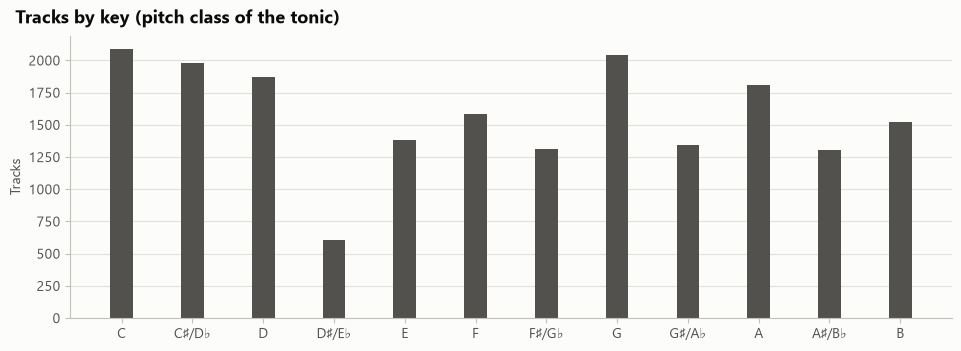

key_name,C,C♯/D♭,D,D♯/E♭,E,F,F♯/G♭,G,G♯/A♭,A,A♯/B♭,B
share,0.111,0.105,0.099,0.032,0.073,0.084,0.069,0.108,0.071,0.096,0.069,0.081


In [ ]:
key_counts = df.key_name.value_counts().reindex(KEY_NAMES)
fig, ax = plt.subplots(figsize=(9.5, 3.4), layout="constrained")
ax.bar(key_counts.index, key_counts.values, color=NEUTRAL, width=0.32)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Tracks")
fig_title(fig, "Tracks by key (pitch class of the tonic)")
plt.show()
(key_counts / len(df)).rename("share").to_frame().T.round(3)

**Observations**

- Keys are used unevenly: C, G and C♯/D♭ are the most common and D♯/E♭ is by far the rarest.
- Without `Mode`, key can't separate major from minor, which is the musically meaningful distinction (mood). Treat key as a secondary categorical filter, not a headline feature.

### 6.3 How the features relate to each other

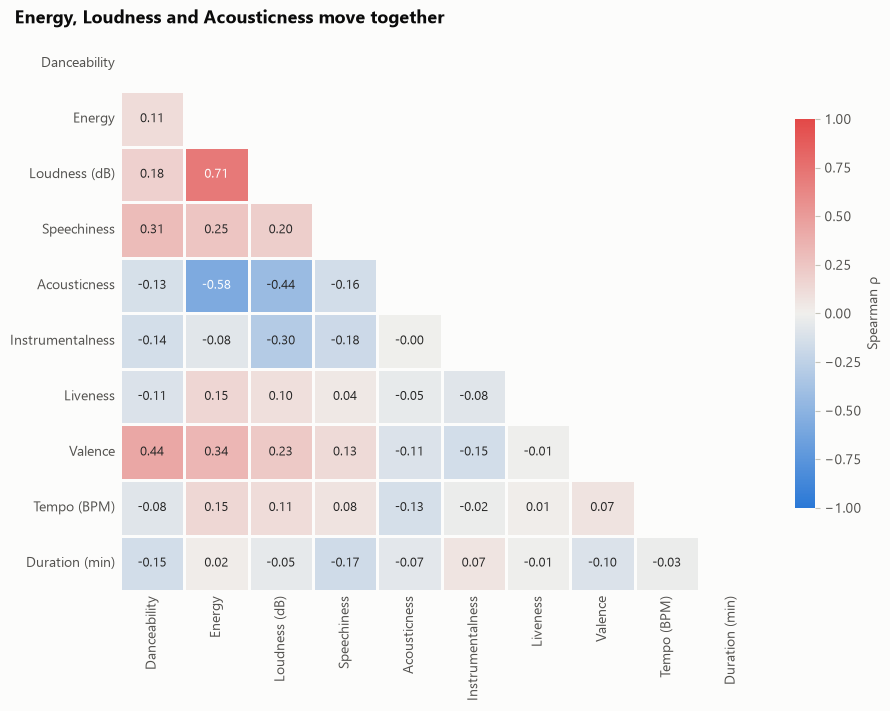

,feature A,feature B,rho
0,Loudness (dB),Energy,0.71
1,Acousticness,Energy,-0.578
2,Acousticness,Loudness (dB),-0.437
3,Valence,Danceability,0.436
4,Valence,Energy,0.343
5,Speechiness,Danceability,0.311


In [ ]:
feature_corr = music[AUDIO_FEATURES].corr(method="spearman").rename(index=FEATURE_LABELS, columns=FEATURE_LABELS)
upper = np.triu(np.ones_like(feature_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8.8, 7), layout="constrained")
sns.heatmap(feature_corr, mask=upper, annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor=SURFACE, cbar_kws={"label": "Spearman ρ", "shrink": 0.7},
            annot_kws={"fontsize": 9}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
fig_title(fig, "Energy, Loudness and Acousticness move together")
plt.show()

names = feature_corr.columns
pairs = pd.DataFrame([(names[i], names[j], feature_corr.iat[i, j]) for i in range(len(names)) for j in range(i)],
                     columns=["feature A", "feature B", "rho"])
pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(6).reset_index(drop=True)

**Observations**

- **Energy and Loudness are strongly correlated (ρ ≈ 0.7), and both move against Acousticness.** Together they form one "intensity" dimension, running from loud, energetic and electric to quiet and acoustic.
- **Danceability and Valence** are moderately linked: danceable songs tend to sound happier.
- Most other pairs are weak, so the remaining features carry fairly independent information.
- **For modelling:** because Energy, Loudness and Acousticness overlap, a regression or SHAP analysis will split credit between them unpredictably. Read them as a group, or reduce them (for example with PCA, next section).

### 6.4 Is there a "hit region" in audio space? (PCA)

PCA compresses the ten standardised features into a few components. If popular tracks had a distinctive audio profile, they would cluster in one region of the first two components. Duration is log-transformed first so that a few very long tracks don't dominate.

The hexagons below show the **share of tracks in that platform's top tier**. Grey marks the 25% base rate, red is above it and blue is below.

Cumulative explained variance: [0.31 0.44 0.55 0.65 0.74 0.82 0.9  0.95 0.98 1.  ]


,PC1 (31% of variance),PC2 (13% of variance),PC3 (11% of variance)
Danceability,0.31,0.55,-0.18
Energy,0.48,-0.23,0.09
Loudness,0.49,-0.16,-0.06
Speechiness,0.15,0.33,0.4
Acousticness,-0.41,0.21,0.02
Instrumentalness,-0.35,-0.02,0.2
Liveness,0.08,-0.26,0.48
Valence,0.32,0.33,-0.05
Tempo,0.11,-0.25,0.5
Duration (log),0.03,-0.47,-0.52


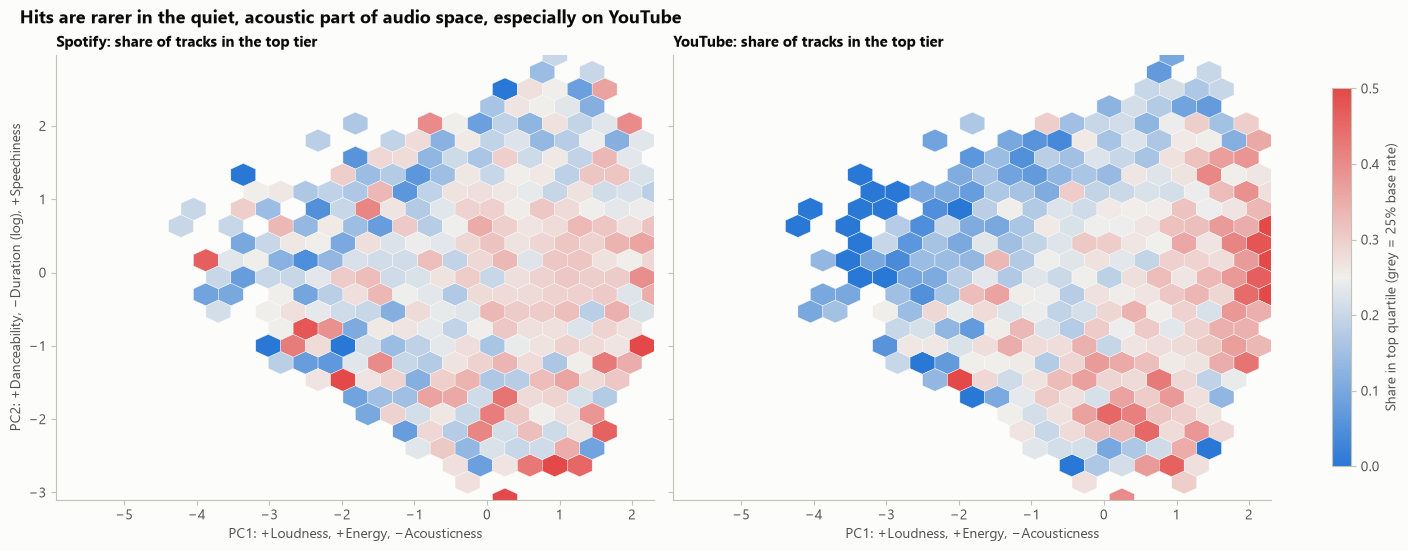

,Spotify,YouTube
PC1 fifth,,
"1 (quietest, most acoustic)",18%,15%
2,24%,24%
3,27%,26%
4,28%,29%
"5 (loudest, most energetic)",28%,32%


In [ ]:
pca_input = music[AUDIO_FEATURES].assign(Duration_ms=np.log10(music.Duration_ms))
scaled = StandardScaler().fit_transform(pca_input)
pca = PCA().fit(scaled)
components = pca.components_.copy()
for i, anchor in [(0, "Loudness"), (1, "Danceability")]:  # PCA signs are arbitrary: make + mean louder / more danceable
    if components[i, AUDIO_FEATURES.index(anchor)] < 0:
        components[i] *= -1
scores = (scaled - pca.mean_) @ components[:2].T

pca_labels = ["Duration (log)" if f == "Duration_ms" else f for f in AUDIO_FEATURES]
loadings = pd.DataFrame(components[:3].T, index=pca_labels,
                        columns=[f"PC{i + 1} ({v:.0%} of variance)" for i, v in enumerate(pca.explained_variance_ratio_[:3])])
print("Cumulative explained variance:", np.round(np.cumsum(pca.explained_variance_ratio_), 2))
display(loadings.round(2))


def axis_name(i):
    top = loadings.iloc[:, i].abs().nlargest(3).index
    return f"PC{i + 1}: " + ", ".join(f"{'+' if loadings.iloc[:, i][f] > 0 else '−'}{f}" for f in top)


extent = (*np.percentile(scores[:, 0], [2, 99.5]), *np.percentile(scores[:, 1], [0.5, 99.5]))  # trim sparse tails
pc1_fifth = pd.qcut(scores[:, 0], 5, labels=["1 (quietest, most acoustic)", "2", "3", "4", "5 (loudest, most energetic)"])
hit_rate = {}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), layout="constrained", sharex=True, sharey=True)
for ax, (name, keep) in zip(axes, [("Spotify", music.Stream.notna()), ("YouTube", music.yt_primary)]):
    keep = keep.to_numpy()
    is_top = (music[f"{name.lower()}_tier"] == TOP_TIER).to_numpy()[keep].astype(float)
    hit_rate[name] = pd.Series(is_top).groupby(pc1_fifth[keep], observed=True).mean()
    hb = ax.hexbin(scores[keep, 0], scores[keep, 1], C=is_top, reduce_C_function=np.mean, gridsize=24,
                   extent=extent, mincnt=10, cmap=DIV_CMAP, vmin=0, vmax=0.5, linewidths=0.3, edgecolors=SURFACE)
    ax.set_title(f"{name}: share of tracks in the top tier")
    ax.set_xlabel(axis_name(0))
    ax.grid(False)
axes[0].set_xlim(extent[0], extent[1])
axes[0].set_ylim(extent[2], extent[3])
axes[0].set_ylabel(axis_name(1))
fig.colorbar(hb, ax=axes, label="Share in top quartile (grey = 25% base rate)", shrink=0.85)
fig_title(fig, "Hits are rarer in the quiet, acoustic part of audio space, especially on YouTube")
plt.show()

pd.DataFrame(hit_rate).rename_axis("PC1 fifth").map("{:.0%}".format)

**Observations**

- The first two components explain only 44% of the variance, so audio space doesn't reduce neatly to two dimensions.
  - PC1 (31%) is the **"intensity" axis**: loud, energetic tracks on the right; quiet, acoustic, instrumental ones on the left.
  - PC2 (13%) roughly contrasts short, danceable, speechy tracks with longer, less danceable ones.
- **The hit rate rises along PC1 on both platforms** (table above):
  - **YouTube:** from 15% in the quietest, most acoustic fifth of tracks to 32% in the loudest, most energetic fifth.
  - **Spotify:** from 18% to 28%, levelling off after the middle fifth.
- **The clearest signal is at the quiet end.** The quietest, most acoustic fifth rarely produces hits on either platform. Even the loudest fifth has only about a 1-in-3 hit rate, against the 1-in-4 base rate.
- Top-tier tracks occur throughout audio space, and no region is made mostly of hits. This anticipates §7: **audio features shift the odds, especially on YouTube, but separate hits from non-hits only weakly.**

## 7. Audio features vs popularity

This section answers the guiding question from four angles:

1. The correlation of each feature with popularity on each platform.
2. How feature averages change from Q1 to Q4.
3. Whether video type and other context confound the results.
4. How much of the association is really about *which artist* it is.

All four use music tracks only (spoken word excluded). Spotify uses one row per track and YouTube one row per video. With ~18,000 tracks even ρ = 0.02 is "statistically significant", so p-values are uninformative here and **the size of ρ is what matters**.

### 7.1 Which features are associated with popularity, and on which platform?

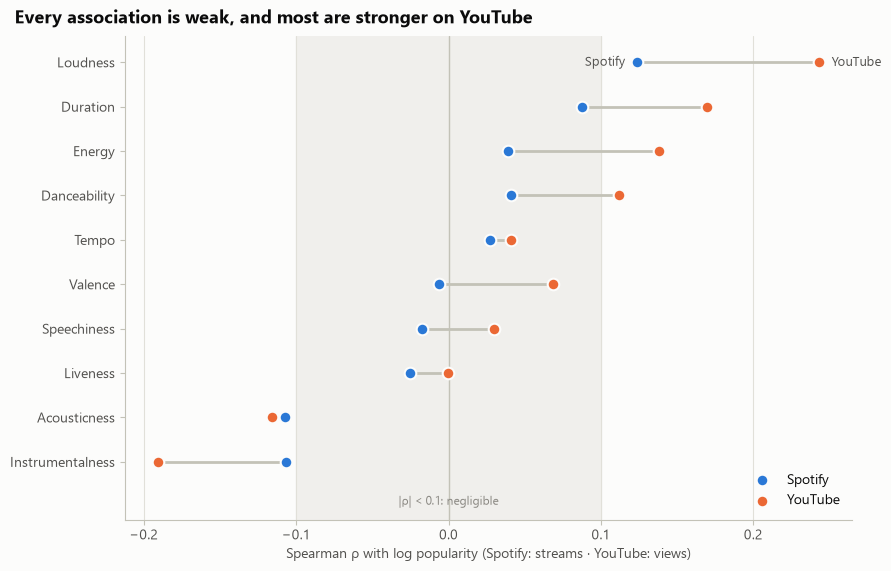

,Spotify,YouTube,YouTube − Spotify
Instrumentalness,-0.107,-0.191,-0.084
Acousticness,-0.107,-0.116,-0.009
Liveness,-0.025,-0.00,0.025
Speechiness,-0.017,0.03,0.047
Valence,-0.006,0.069,0.075
Tempo (BPM),0.027,0.041,0.014
Danceability,0.041,0.112,0.071
Energy,0.039,0.138,0.099
Duration (min),0.087,0.169,0.082
Loudness (dB),0.124,0.243,0.119


In [ ]:
def spearman_table(frames):
    '''Spearman ρ of every audio feature with popularity, one column per (frame, target) pair.'''
    return pd.DataFrame({name: {f: stats.spearmanr(data[f], data[target]).statistic for f in AUDIO_FEATURES}
                         for name, (data, target) in frames.items()})


rho = spearman_table({"Spotify": (music_sp, "log_stream"), "YouTube": (music_yt, "log_views")})
rho = rho.loc[rho.mean(axis=1).sort_values().index]
rho_labels = [FEATURE_LABELS.get(f, f).split(" (")[0] for f in rho.index]
ypos = np.arange(len(rho))

fig, ax = plt.subplots(figsize=(8.8, 5.6), layout="constrained")
ax.axvspan(-0.1, 0.1, color=MIDPOINT, zorder=0)
ax.axvline(0, color=FAINT, linewidth=1)
ax.hlines(ypos, rho.min(axis=1), rho.max(axis=1), color=FAINT, linewidth=2, zorder=1)
for platform, colour in PLATFORM_COLOURS.items():
    ax.scatter(rho[platform], ypos, s=70, color=colour, edgecolor=SURFACE, linewidth=1.5, zorder=3, label=platform)
top_row = rho.iloc[-1]
low, high = sorted(PLATFORM_COLOURS, key=lambda p: top_row[p])
ax.annotate(low, (top_row[low], ypos[-1]), xytext=(-9, 0), textcoords="offset points", ha="right", va="center", fontsize=9, color=NEUTRAL)
ax.annotate(high, (top_row[high], ypos[-1]), xytext=(9, 0), textcoords="offset points", ha="left", va="center", fontsize=9, color=NEUTRAL)
ax.text(0, -0.9, "|ρ| < 0.1: negligible", ha="center", va="center", fontsize=8.5, color=MUTED)
ax.set_ylim(-1.3, len(rho) - 0.4)
ax.set_yticks(ypos, rho_labels)
ax.set_xlabel("Spearman ρ with log popularity (Spotify: streams · YouTube: views)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig_title(fig, "Every association is weak, and most are stronger on YouTube")
plt.show()

rho.assign(**{"YouTube − Spotify": rho.YouTube - rho.Spotify}).rename(index=FEATURE_LABELS).round(3)

**Observations**

- **Nothing is strong.** The largest |ρ| is 0.24, so no single audio feature orders tracks by popularity to any useful degree.
- **Loudness** is the strongest association on both platforms (ρ ≈ 0.12 on Spotify, 0.24 on YouTube). **Duration, Energy and Danceability** are also positive, and all are clearly stronger on YouTube.
- **Instrumentalness and Acousticness** are negative on both platforms (ρ ≈ −0.11 on Spotify). Instrumentalness is especially negative on YouTube (−0.19).
- **Speechiness, Liveness, Valence and Tempo are negligible** (inside the grey band). Mood and tempo say almost nothing about popularity.
- **Medium difference:** the signs mostly agree across platforms, but for Loudness, Energy, Danceability and Duration the YouTube association is two to three times larger. YouTube rewards the "intense, danceable" profile more than Spotify does, although §7.3 shows that part of this comes from the kind of video.

### 7.2 Tier profiles: how the average track changes from Q1 to Q4

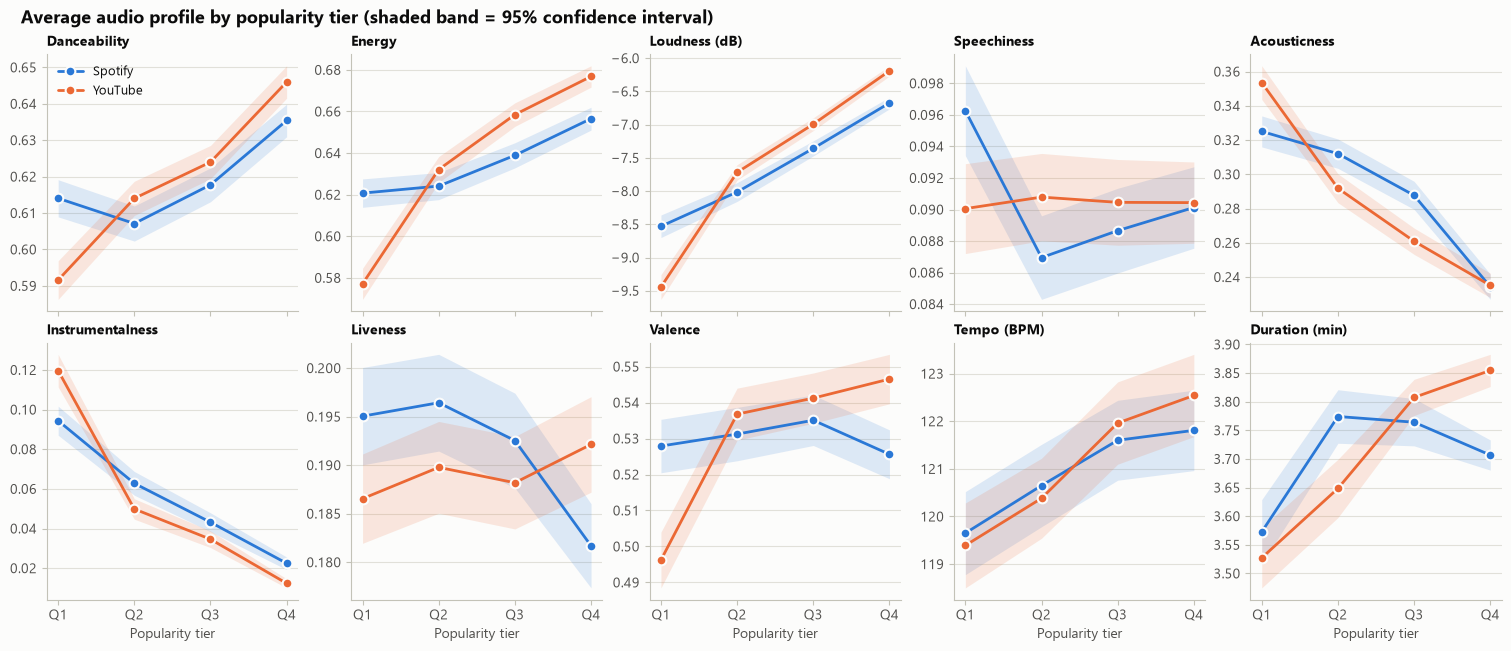

,Spotify Q1,Spotify Q4,YouTube Q1,YouTube Q4
Danceability,0.614,0.635,0.592,0.646
Energy,0.621,0.657,0.577,0.677
Loudness (dB),-8.53,-6.67,-9.44,-6.19
Speechiness,0.096,0.09,0.09,0.09
Acousticness,0.325,0.234,0.354,0.235
Instrumentalness,0.094,0.022,0.12,0.012
Liveness,0.195,0.182,0.187,0.192
Valence,0.528,0.526,0.496,0.547
Tempo (BPM),119.65,121.81,119.39,122.54
Duration (min),3.57,3.71,3.53,3.85


In [ ]:
def tier_profile(data, tier_col, feature):
    grouped = feature_values(data, feature).groupby(data[tier_col], observed=True)
    return grouped.mean(), 1.96 * grouped.sem()


x = np.arange(len(TIER_LABELS))
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4), layout="constrained", sharex=True)
for ax, feature in zip(axes.flat, AUDIO_FEATURES):
    for platform, data, tier_col, _ in PLATFORM_FRAMES:
        mean, ci = tier_profile(data, tier_col, feature)
        colour = PLATFORM_COLOURS[platform]
        ax.fill_between(x, mean - ci, mean + ci, color=colour, alpha=0.15, linewidth=0)
        ax.plot(x, mean, color=colour, marker="o", markeredgecolor=SURFACE, markeredgewidth=1.5, label=platform)
    ax.set_title(FEATURE_LABELS.get(feature, feature), fontsize=10)
    ax.set_xticks(x, ["Q1", "Q2", "Q3", "Q4"])
    ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.set_xlabel("Popularity tier")
axes[0, 0].legend(fontsize=9)
fig_title(fig, "Average audio profile by popularity tier (shaded band = 95% confidence interval)")
plt.show()

pd.DataFrame({f"{platform} {q}": [tier_profile(data, tier_col, f)[0].iloc[i] for f in AUDIO_FEATURES]
              for platform, data, tier_col, _ in PLATFORM_FRAMES for q, i in (("Q1", 0), ("Q4", -1))},
             index=[FEATURE_LABELS.get(f, f) for f in AUDIO_FEATURES]).round(3)

**Observations**

- **On YouTube, the average track changes steadily from Q1 to Q4.** It becomes:
  - louder (−9.4 → −6.2 dB);
  - more energetic (0.58 → 0.68);
  - more danceable (0.59 → 0.65);
  - happier (0.50 → 0.55);
  - less acoustic (0.35 → 0.24) and less instrumental (0.12 → 0.01).
- **Spotify moves the same way on Loudness, Energy, Acousticness and Instrumentalness, with gentler slopes** (Loudness −8.5 → −6.7 dB, Energy 0.62 → 0.66). Valence doesn't change on Spotify.
- **The shifts are modest in absolute terms.** A Q4 track isn't a different kind of track from a Q1 track, just somewhat more "intense" on average.
- **Each panel has its own zoomed y-axis.** Speechiness and Liveness look wiggly but move by less than 0.02, and Tempo by about 3 BPM, so they are flat in practice.
- This small-multiples view makes a good **dashboard component**: the tiers act as the filter, the two platform lines allow direct comparison, and the size of each change is visible.

### 7.3 Confounders: video type, official status, album type, collaborations

Some non-audio factors could drive popularity and also correlate with audio features. If they do, the associations above partly reflect them.

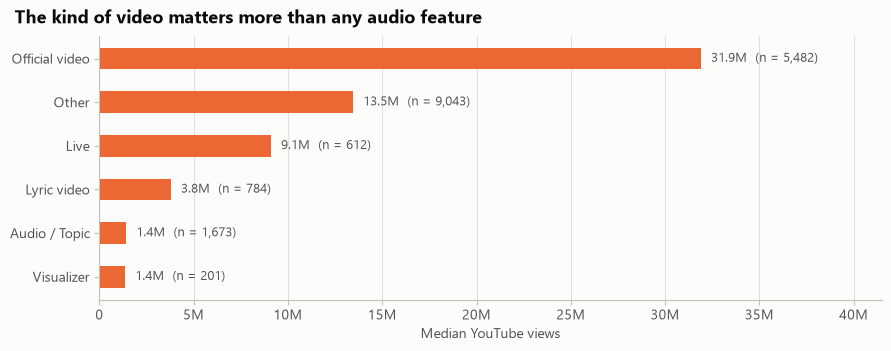

videos median_views
official_video Licensed                     
False          False       3977         1.9M
True           False       1387         8.8M
               True       12431        24.6M

In [ ]:
by_type = (music_yt.groupby("video_type", observed=True)
           .agg(videos=("Views", "size"), median_views=("Views", "median"))
           .sort_values("median_views"))

fig, ax = plt.subplots(figsize=(8.8, 3.4), layout="constrained")
ax.barh(by_type.index.astype(str), by_type.median_views, color=YOUTUBE, height=0.5)
for y, (m, n) in enumerate(zip(by_type.median_views, by_type.videos)):
    ax.text(m + by_type.median_views.max() * 0.01, y, f" {human(m)}  (n = {n:,})", va="center", fontsize=9, color=NEUTRAL)
ax.set_xlim(0, by_type.median_views.max() * 1.3)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: human(v)))
ax.set_xlabel("Median YouTube views")
ax.grid(axis="y", visible=False)
fig_title(fig, "The kind of video matters more than any audio feature")
plt.show()

(music_yt.groupby(["official_video", "Licensed"])
 .agg(videos=("Views", "size"), median_views=("Views", "median"))
 .assign(median_views=lambda d: human_col(d.median_views)))

In [ ]:
official_mv = music_yt[music_yt.video_type == "Official video"]
audio_only = music_yt[music_yt.video_type == "Audio / Topic"]
spearman_table({"All videos": (music_yt, "log_views"),
                f"Official music videos only (n={len(official_mv):,})": (official_mv, "log_views"),
                f"Audio / Topic uploads only (n={len(audio_only):,})": (audio_only, "log_views")}
               ).rename(index=FEATURE_LABELS).round(3)

,All videos,"Official music videos only (n=5,482)","Audio / Topic uploads only (n=1,673)"
Danceability,0.112,0.089,0.169
Energy,0.138,0.039,0.138
Loudness (dB),0.243,0.158,0.207
Speechiness,0.03,0.024,0.046
Acousticness,-0.116,-0.035,-0.154
Instrumentalness,-0.191,-0.147,-0.277
Liveness,-0.00,-0.019,-0.007
Valence,0.069,0.032,0.141
Tempo (BPM),0.041,-0.006,0.067
Duration (min),0.169,0.167,0.216


In [ ]:
def medians_by(col):
    return pd.DataFrame({
        "tracks": music.groupby(col).size(),
        "Spotify median streams": human_col(music_sp.groupby(col).Stream.median()),
        "YouTube median views": human_col(music_yt.groupby(col).Views.median()),
    })


display(medians_by("Album_type"))
medians_by("is_collab")

,tracks,Spotify median streams,YouTube median views
Album_type,,,
album,13835,56.6M,15.6M
compilation,689,42.4M,8.1M
single,4201,28.5M,9M


,tracks,Spotify median streams,YouTube median views
is_collab,,,
False,17277,48.3M,12.8M
True,1448,61.7M,29.7M


**Observations**

- **Video type is the biggest single factor on YouTube.** Official music videos have a median of ~32M views, against ~1.4M for audio-only or Topic uploads, a gap of more than 20×. No audio feature comes close.
- Licensed, official videos have a median of ~25M views, against ~1.9M for videos that are neither (~13×). Video type is still the sharper variable, because `official_video` also covers audio-only uploads.
- **Within official music videos only, the YouTube associations shrink.**
  - Energy (0.138 → 0.039) and Acousticness (−0.116 → −0.035) fall to or below Spotify's level, and Loudness falls most of the way (0.243 → 0.158).
  - Danceability, Instrumentalness and Duration stay somewhat stronger than on Spotify.
  - Part of YouTube's stronger audio signal (§7.1) is therefore a **composition effect**: loud, energetic pop is more likely to have a proper music video, and music videos get far more views.
- Within audio-only uploads the associations stay (Instrumentalness is even more negative), but that group is small (~1,700 videos).
- **Collaborations** have higher medians on both platforms: 62M vs 48M streams, and 30M vs 13M views. **Album tracks** out-stream singles by about 2×, probably because the best-known album tracks of established artists dominate the top-10 lists.
- **For the dashboard:** offer a "video type" filter, or at least an "official music videos only" toggle, so YouTube comparisons are like-for-like.

### 7.4 The artist effect

The dataset is built from each artist's top 10, so tracks are clustered by artist. If most of the variation in popularity lies *between* artists, then pooled correlations partly measure "what big artists' songs sound like" rather than "what makes a song do better".

To separate the two:
1. Split the popularity variance into a between-artist part and a within-artist part.
2. Recompute the correlations **within artists**, by subtracting each artist's mean from both the feature and the popularity.

Only artists with at least two tracks in the frame are used.

,tracks,artists,share of variance between artists,expected share if artists didn't matter
Spotify,"18,208","2,040",0.54,0.11
YouTube,"17,761","2,014",0.43,0.11


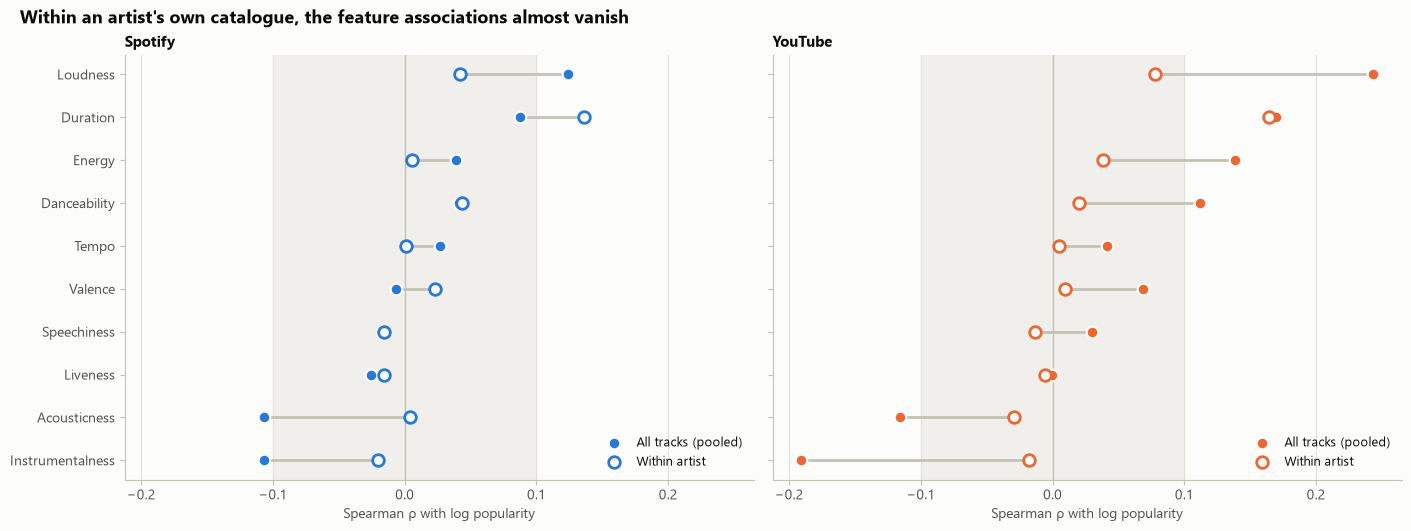

pooled         within artist        
                 Spotify YouTube       Spotify YouTube
Instrumentalness  -0.107  -0.191        -0.021  -0.018
Acousticness      -0.107  -0.116         0.004  -0.029
Liveness          -0.025   -0.00        -0.016  -0.006
Speechiness       -0.017    0.03        -0.016  -0.013
Valence           -0.006   0.069         0.023    0.01
Tempo (BPM)        0.027   0.041         0.001   0.005
Danceability       0.041   0.112         0.044    0.02
Energy             0.039   0.138         0.005   0.038
Duration (min)     0.087   0.169         0.136   0.164
Loudness (dB)      0.124   0.243         0.042   0.078

In [ ]:
def with_multiple_tracks(data):
    return data[data.groupby("Artist").Artist.transform("size") >= 2]


def between_artist_share(data, col):
    within = data[col] - data.groupby("Artist")[col].transform("mean")
    return 1 - within.var() / data[col].var()


rows, rho_within = {}, {}
for platform, data, _, target in PLATFORM_FRAMES:
    data = with_multiple_tracks(data)
    rows[platform] = {"tracks": len(data), "artists": data.Artist.nunique(),
                      "share of variance between artists": between_artist_share(data, target),
                      "expected share if artists didn't matter": (data.Artist.nunique() - 1) / (len(data) - 1)}
    demeaned = data[AUDIO_FEATURES + [target]] - data.groupby("Artist")[AUDIO_FEATURES + [target]].transform("mean")
    rho_within[platform] = {f: stats.spearmanr(demeaned[f], demeaned[target]).statistic for f in AUDIO_FEATURES}
display(pd.DataFrame(rows).T.round(2))
rho_within = pd.DataFrame(rho_within).loc[rho.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained", sharex=True, sharey=True)
for ax, platform in zip(axes, PLATFORM_COLOURS):
    colour, pooled, within = PLATFORM_COLOURS[platform], rho[platform], rho_within[platform]
    ax.axvspan(-0.1, 0.1, color=MIDPOINT, zorder=0)
    ax.axvline(0, color=FAINT, linewidth=1)
    ax.hlines(ypos, np.minimum(pooled, within), np.maximum(pooled, within), color=FAINT, linewidth=2, zorder=1)
    ax.scatter(pooled, ypos, s=70, color=colour, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="All tracks (pooled)")
    ax.scatter(within, ypos, s=70, facecolor=SURFACE, edgecolor=colour, linewidth=2, zorder=3, label="Within artist")
    ax.set_title(platform)
    ax.set_xlabel("Spearman ρ with log popularity")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", fontsize=9)
axes[0].set_yticks(ypos, rho_labels)
fig_title(fig, "Within an artist's own catalogue, the feature associations almost vanish")
plt.show()

pd.concat({"pooled": rho, "within artist": rho_within}, axis=1).rename(index=FEATURE_LABELS).round(3)

**Observations**

- **54% (Spotify) and 43% (YouTube) of the variance in log popularity lies between artists.** Grouping by artist would produce only ~11% by chance. *Who* the artist is matters more than any audio feature.
- **Within an artist's own tracks, the associations for Loudness, Energy, Acousticness and Instrumentalness collapse to |ρ| ≤ 0.08.**
- **Duration is the exception.** Its association holds on YouTube and even strengthens on Spotify (0.09 → 0.14), which makes it the one feature with a genuine track-level link. One possible reason is that an artist's shortest tracks include interludes, intros and edits.
- The pooled associations in §7.1 therefore mostly describe **which kinds of artists and genres are big** (loud, energetic, non-acoustic pop). They say little about why one song beats another by the same artist.

## 8. Key findings and implications

In [ ]:
strongest = lambda s: f"{FEATURE_LABELS.get(s.abs().idxmax(), s.abs().idxmax()).split(' (')[0]} (ρ = {s[s.abs().idxmax()]:+.2f})"
pd.Series({
    "Raw rows → clean tracks": f"{len(raw):,} → {len(df):,}",
    "Artists": f"{df.Artist.nunique():,}",
    "Tracks with both Stream and Views": f"{(df.Stream.notna() & df.Views.notna()).sum():,}",
    "Spotify 'popular' (Q4) threshold": f"≥ {human(10 ** TIER_CUTS['Spotify'][-1] - 1)} streams",
    "YouTube 'popular' (Q4) threshold": f"≥ {human(10 ** TIER_CUTS['YouTube'][-1] - 1)} views",
    "Spearman ρ, streams vs views": f"{rho_platforms:.2f}",
    "Same tier on both platforms": f"{exact:.0%} (within one tier: {within_one:.0%})",
    "Strongest feature association, Spotify": strongest(rho.Spotify),
    "Strongest feature association, YouTube": strongest(rho.YouTube),
    "Popularity variance between artists (Spotify / YouTube)":
        f"{rows['Spotify']['share of variance between artists']:.0%} / {rows['YouTube']['share of variance between artists']:.0%}",
}, name="value").to_frame()

,value
Raw rows → clean tracks,"20,718 → 18,847"
Artists,"2,072"
Tracks with both Stream and Views,"17,945"
Spotify 'popular' (Q4) threshold,≥ 134.7M streams
YouTube 'popular' (Q4) threshold,≥ 65.5M views
"Spearman ρ, streams vs views",0.62
Same tier on both platforms,47% (within one tier: 86%)
"Strongest feature association, Spotify",Loudness (ρ = +0.12)
"Strongest feature association, YouTube",Loudness (ρ = +0.24)
Popularity variance between artists (Spotify / YouTube),54% / 43%


### What the data is
- **18,847 clean tracks from ~2,070 artists**, each artist contributing its top 10 Spotify tracks. It is a **sample of hits**, so "low popularity" means *less popular among successful tracks*.
- Collaborations were duplicated once per credited artist. They are now deduplicated, with the artist count kept as `n_artists`.
- **`Mode` does not exist in this dataset**, so Table 1 of the proposal needs updating.
- **The YouTube match is not always the song's main video.** ~1.4% of matches look like the wrong recording, some global hits are matched to minor re-uploads, and `official_video` doesn't mean "music video". The flags `yt_title_match` and `video_type` handle part of this. **`Views` measures the matched upload, not the song's whole YouTube audience.**

### Popularity
- The proposal's log transform and per-platform quartile tiers work well. **Popular = at least ~135M streams on Spotify, or at least ~66M views on YouTube.** YouTube popularity is far more unequal than Spotify's.
- Likes and Comments add almost nothing beyond Views as popularity measures. Like-rate is useful as a separate engagement lens.
- **The platforms agree only moderately** (ρ ≈ 0.62; 47% of tracks share a tier). The biggest disagreements are matching artefacts, or regional habits such as Indian film songs, which are watched on YouTube more than streamed on Spotify.

### Audio features and popularity
- **Every association is weak** (|ρ| ≤ 0.24).
  - Loudness, Energy, Danceability and Duration are positive.
  - Acousticness and Instrumentalness are negative.
  - Mood (Valence) and Tempo are negligible.
- **The associations are stronger on YouTube**, where the hit rate climbs clearly toward the loud, energetic end of audio space. Part of this is a composition effect: loud, energetic pop is more likely to have an official music video, which gets far more views. Within official music videos, Energy and Acousticness fall to Spotify's level.
- **Artist identity dominates.** About half of the popularity variance lies between artists, and within an artist's catalogue most feature associations nearly vanish (Duration is the exception). The pooled patterns describe *what popular artists sound like*, not a recipe for a hit.

### Implications for the dashboard (Week 8+)
1. **Frame the dashboard as association and profiling, not prediction.** "What popular tracks tend to sound like on each platform" is supported. "Engineering a hit from audio features" is not, and that nuance can itself be a strong story for the presentation.
2. **Make the popularity tier the main filter**, with side-by-side platform profiles as in §7.2, in consistent Spotify/YouTube colours.
3. **Expose the confounders as filters:** `video_type` (or "official music videos only"), `is_spoken_word`, `yt_title_match`, `Album_type` and `is_collab`.
4. **Add a platform-divergence view** (`platform_lean`) for the "medium-specific preferences" research gap, always read alongside video type.
5. **Consider an artist-relative view** (each track's popularity against its artist's average) to separate song-level from artist-level effects.

### Next steps
- A modelling notebook per platform: regression and gradient boosting with SHAP, as planned in the proposal, plus artist-level controls. Treat Energy, Loudness and Acousticness as one correlated group, via PCA or grouped importance.
- UMAP as a non-linear alternative to the PCA view in §6.4.

## 9. Export the clean table for Tableau

One row per track, UTF-8 encoded, without the long `Description` text. The data dictionary below documents every column added to the original ones.

In [ ]:
EXPORT_COLUMNS = [
    # identifiers and descriptors
    "Uri", "Url_youtube", "Artist", "Track", "Album", "Album_type", "Title", "Channel",
    # audio features
    *AUDIO_FEATURES, "duration_min", "Key", "key_name",
    # popularity
    *POPULARITY, "log_stream", "log_views", "log_likes", "log_comments", "like_rate", "comment_rate",
    "spotify_tier", "youtube_tier", "spotify_popular", "youtube_popular", "lean_score", "platform_lean",
    # context and flags
    "Licensed", "official_video", "video_type", "n_artists", "is_collab", "is_spoken_word", "is_instrumental",
    "is_live", "is_long_track", "yt_video_shared", "yt_primary", "yt_title_match",
]
df[EXPORT_COLUMNS].to_csv(CLEAN_PATH, index=False, encoding="utf-8")

check = pd.read_csv(CLEAN_PATH)
assert len(check) == len(df) and check.Uri.is_unique and "Description" not in check.columns
print(f"Wrote {CLEAN_PATH.relative_to(ROOT)}: {len(check):,} rows × {check.shape[1]} columns, "
      f"{CLEAN_PATH.stat().st_size / 1e6:.1f} MB")

Wrote dataset\spotify_youtube_clean.csv: 18,847 rows × 49 columns, 10.6 MB


In [ ]:
DATA_DICTIONARY = {
    "duration_min": "Track length in minutes",
    "key_name": "Key as a pitch name (C, C♯/D♭, …); Mode is not available in the data",
    "log_stream, log_views, log_likes, log_comments": "log10(count + 1): 6 = one million, 9 = one billion",
    "like_rate, comment_rate": "Likes / comments per view: engagement independent of reach",
    "spotify_tier, youtube_tier": "Quartile of streams / views within that platform: Q1 (Low) … Q4 (Top)",
    "spotify_popular, youtube_popular": "True if the track is in its platform's top tier (the proposal's 'popular')",
    "lean_score": "log10 views minus the views expected from streams (+1 = 10× more views than typical)",
    "platform_lean": "Spotify-leaning (bottom 20% of lean_score) / Balanced / YouTube-leaning (top 20%)",
    "video_type": "Official video, Lyric video, Live, Audio / Topic, Visualizer, Other (no keyword) or No video",
    "n_artists, is_collab": "Number of credited artists the track was listed under; collaboration if more than one",
    "is_spoken_word": "Speechiness > 0.66 (audiobooks etc.); excluded from the feature analysis",
    "is_instrumental, is_live, is_long_track": "Instrumentalness > 0.5 / Liveness > 0.8 / longer than 10 minutes",
    "yt_video_shared": "The YouTube video is also matched to another Spotify track",
    "yt_primary": "Filter on this to count each YouTube video once",
    "yt_title_match": "YouTube title contains the track name (blank = no video or non-Latin title)",
}
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(DATA_DICTIONARY, name="meaning").rename_axis("column").to_frame())

,meaning
column,
duration_min,Track length in minutes
key_name,"Key as a pitch name (C, C♯/D♭, …); Mode is not available in the data"
"log_stream, log_views, log_likes, log_comments","log10(count + 1): 6 = one million, 9 = one billion"
"like_rate, comment_rate",Likes / comments per view: engagement independent of reach
"spotify_tier, youtube_tier",Quartile of streams / views within that platform: Q1 (Low) … Q4 (Top)
"spotify_popular, youtube_popular",True if the track is in its platform's top tier (the proposal's 'popular')
lean_score,log10 views minus the views expected from streams (+1 = 10× more views than typical)
platform_lean,Spotify-leaning (bottom 20% of lean_score) / Balanced / YouTube-leaning (top 20%)
video_type,"Official video, Lyric video, Live, Audio / Topic, Visualizer, Other (no keyword) or No video"
